# Čarađe 2024 — How complete is the catalogue, and what can a 7-station detector realistically find?
### Worked modelling solution built on Milena's EDA (DSB Capstone)

**Prediction question**

> *For an aftershock of magnitude M in the Čarađe study area, what is the probability that each of the seven stations (BRY, CEME, DRME, HCY, KOME, NKME, UPM) records a pickable P arrival — and therefore, what is the smallest magnitude the network reliably detects under a "≥ k stations" rule?*

Why this question? The capstone asks whether automatic detection can add small events to the catalogue. Before judging a detector by its recall, we need to know three things the existing notebooks do not quantify:

1. **How many events are probably missing** (Gutenberg–Richter, done with a defensible Mc and b-value).
2. **What recall is realistic** for a P-only, ≥ 5-station rule on this network (a supervised detection-probability model trained on the analysts' bulletin picks).
3. **Which stage of the pipeline loses the events** — picking, association, or location and filtering (the capstone's own locator re-run on the analysts' picks).

Parts 1–8 use only the two public files in the repository, so they run end-to-end in Colab without the Drive waveforms. Part 9 contains optional cells that run on the result tables already saved on Drive by the Modeling notebook.

**Course materials used:** model workflow, train/test split & cross-validation, logistic regression, classification metrics, ROC-AUC, imbalanced data (threshold moving, `class_weight`), GridSearch + Pipelines, ensembles (random forest, gradient boosting), model explainability (coefficients, permutation importance), time-series thinking (temporal hold-out instead of a random split).

| Part | Content |
|---|---|
| 1 | Data loading and EDA validation (duplicates, near-duplicates, depth flags, network geometry) |
| 2 | Magnitude of completeness and b-value, done robustly; expected number of missing events |
| 3 | Building the modelling table (event × station) and avoiding leakage |
| 4 | Models: baselines → logistic regression → ensembles, with grouped CV and a temporal hold-out |
| 5 | Interpretation: per-station detection curves |
| 6 | Network level: testing independence, a drift in the reference, and a recall benchmark for a ≥ 5-station detector |
| 7 | Where the events are lost: the capstone locator on analyst picks, depth bounds and the search-boundary filter |
| 8 | Checking the headline metrics, with confidence intervals |
| 9 | Optional: re-evaluate the saved Drive results and run a blind review |
| 10 | Conclusions and next steps |

## 0. Imports and settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             balanced_accuracy_score, recall_score, precision_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_curve)
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

BASE = "https://raw.githubusercontent.com/milena-seismo/DSB_capstone/refs/heads/main/"
CATALOGUE_URL = BASE + "2024_radna_kopija.csv"
PICKS_URL = BASE + "march2024_station_phase_picks.csv"

# Study area and mainshock, as defined in the EDA notebook
LAT0, LON0, RADIUS_KM = 42.974, 18.661, 30
MAINSHOCK_UTC = pd.Timestamp("2024-03-14 03:06:46.30", tz="UTC")

## 1. Data loading and EDA validation

The steps below reproduce the EDA notebook's cleaning, then add four checks that matter for the modelling stage:

* **near-duplicates** (the exact-duplicate check cannot find two solutions of the same event a fraction of a second apart, and the Modeling notebook matches events within ±2 s);
* **depth quality flags** instead of overwriting depths with 10 km;
* **network geometry** (azimuthal gap), which controls how well any locator can resolve depth;
* a reconciliation of the **catalogue and the phase-pick export**, so both reference sets are shown to describe the same events.

In [2]:
kat = pd.read_csv(CATALOGUE_URL)
print("Raw catalogue:", kat.shape, "| exact duplicates:", kat.duplicated().sum())
kat = kat.drop_duplicates().reset_index(drop=True)

kat["origin_utc"] = (
    pd.to_datetime(kat[["year", "month", "day", "hour", "minute"]], utc=True)
    + pd.to_timedelta(kat["second"], unit="s")
).astype("datetime64[ns, UTC]")
kat = kat.rename(columns={"magnitude_ML_or_Md": "mag"})

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371 * np.arcsin(np.sqrt(a))

kat["dist_main_km"] = haversine_km(LAT0, LON0, kat["latitude_deg"], kat["longitude_deg"])

# Quality flags (keep the original values; let downstream steps decide)
kat["depth_fixed_flag"] = kat["depth_sd_km"].eq(11.1)   # 11.1 km = default uncertainty
kat["depth_zero_flag"] = kat["depth_km"].eq(0)

study = kat[kat["dist_main_km"] <= RADIUS_KM].sort_values("origin_utc").copy()
print("Events within 30 km during 2024:", len(study))
print("Events 14–20 March (EDA reference window):",
      study["origin_utc"].between("2024-03-14", "2024-03-21", inclusive="left").sum())

Raw catalogue: (2293, 16) | exact duplicates: 1
Events within 30 km during 2024: 906
Events 14–20 March (EDA reference window): 337


**Validated.** 2,292 unique events, 906 within the 30 km circle and 337 in 14–20 March — the EDA figures reproduce exactly.

### 1.1 Near-duplicates

In [3]:
s = study.sort_values("origin_utc").copy()
s["dt_prev_s"] = s["origin_utc"].diff().dt.total_seconds()
s["sep_prev_km"] = haversine_km(s["latitude_deg"].shift(), s["longitude_deg"].shift(),
                                s["latitude_deg"], s["longitude_deg"])
close = s[s["dt_prev_s"] <= 2.0]
print("Consecutive study-area events ≤ 2 s apart:", len(close))
display(close[["origin_utc", "mag", "latitude_deg", "longitude_deg", "depth_km",
               "dt_prev_s", "sep_prev_km"]].round(3))

Consecutive study-area events ≤ 2 s apart: 3


/tmp/ipykernel_260/1945230655.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "dt_prev_s", "sep_prev_km"]].round(3))


,origin_utc,mag,latitude_deg,longitude_deg,depth_km,dt_prev_s,sep_prev_km
403,2024-03-14 03:19:25.690000+00:00,2.2,42.983,18.683,13.6,0.72,4.000
298,2024-03-14 04:50:23.050000+00:00,1.8,42.998,18.635,11.7,0.34,3.773
1263,2024-06-05 02:09:38.690000+00:00,1.2,42.804,18.852,0.0,1.59,12.697


These pairs are a few kilometres apart in less than a second. They may be two real events with overlapping waveforms or two solutions of one event. Either way they deserve an analyst look, and they matter for one-to-one matching at ±2 s: two reference events this close compete for the same detection.

### 1.2 Depth flags and network geometry

Study-area aftershocks 14–31 March: 402
  depth = 0 km: 11 | default depth uncertainty (11.1 km): 16


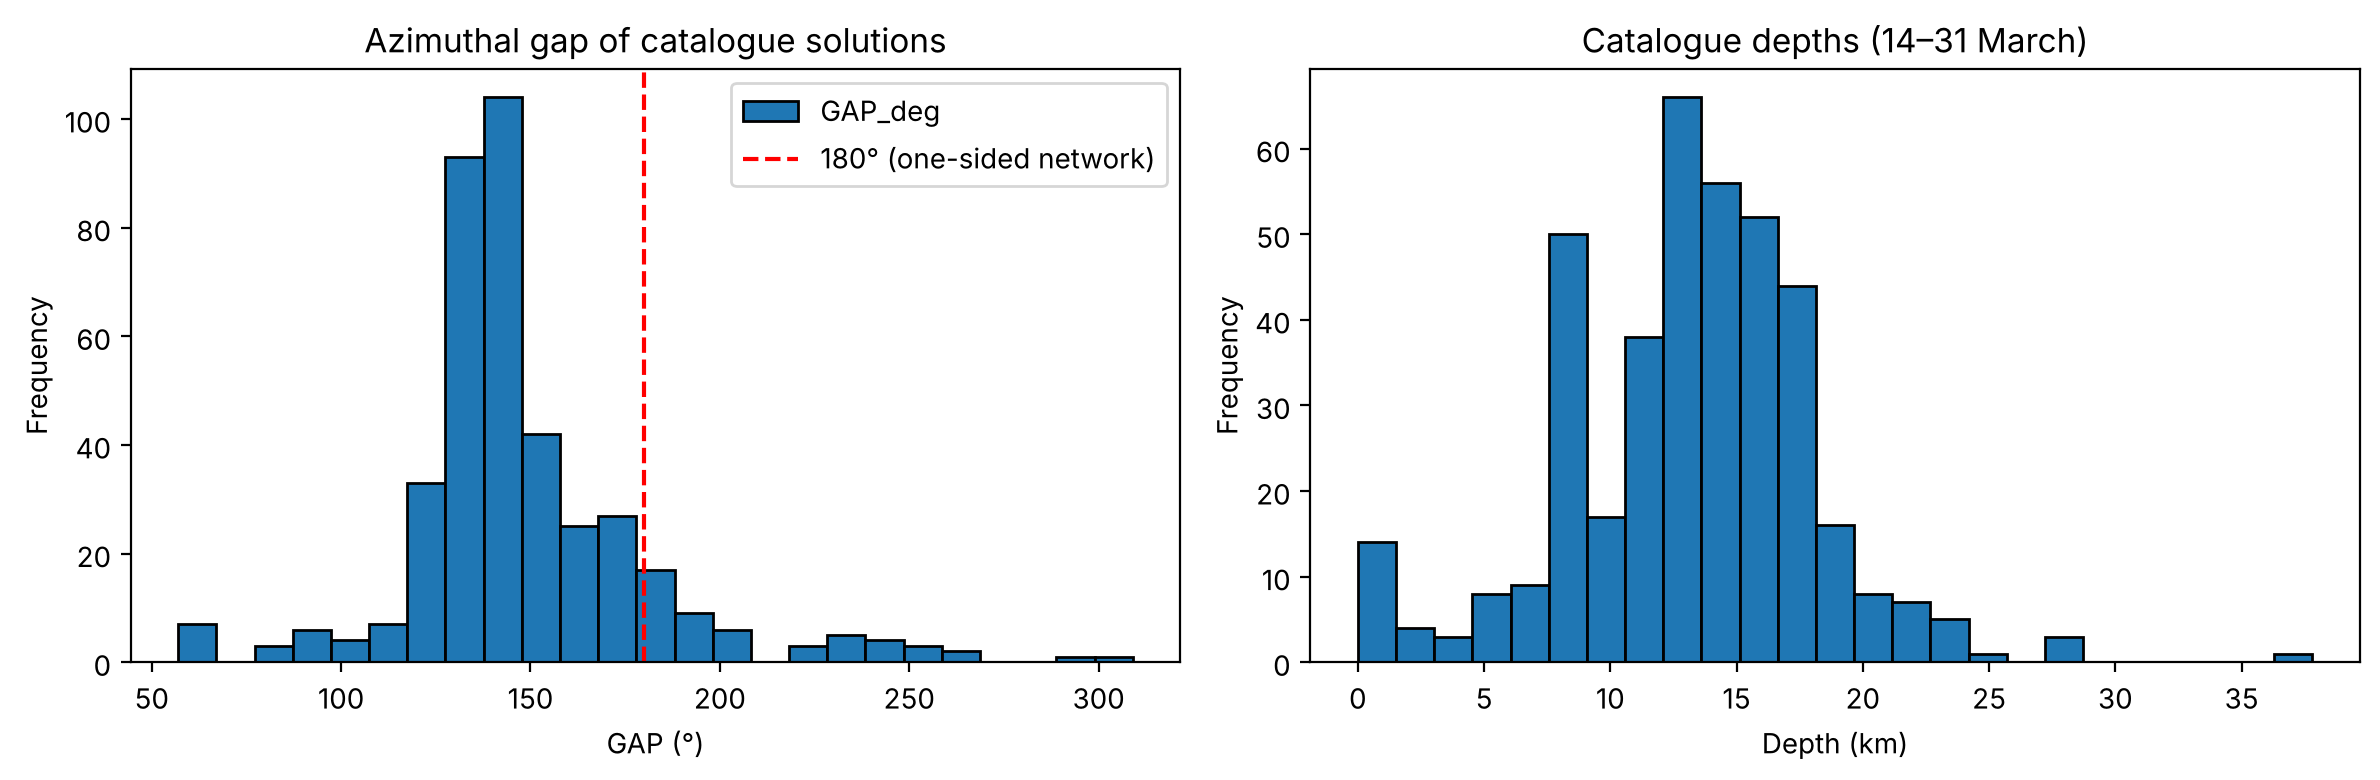

Median azimuthal gap: 142.0 °


In [4]:
after_main = study[(study["origin_utc"] > MAINSHOCK_UTC) & (study["origin_utc"] < "2024-04-01")]
print("Study-area aftershocks 14–31 March:", len(after_main))
print("  depth = 0 km:", after_main["depth_zero_flag"].sum(),
      "| default depth uncertainty (11.1 km):", after_main["depth_fixed_flag"].sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
after_main["GAP_deg"].plot.hist(bins=25, ax=axes[0], edgecolor="k")
axes[0].axvline(180, color="r", ls="--", label="180° (one-sided network)")
axes[0].set(title="Azimuthal gap of catalogue solutions", xlabel="GAP (°)")
axes[0].legend()
after_main["depth_km"].plot.hist(bins=25, ax=axes[1], edgecolor="k")
axes[1].set(title="Catalogue depths (14–31 March)", xlabel="Depth (km)")
plt.tight_layout(); plt.show()
print("Median azimuthal gap:", after_main["GAP_deg"].median(), "°")

The median catalogue gap is about 140° even though the catalogue uses many more stations than the seven in the capstone. With seven stations (none to the west or north-west of the sequence), the geometry is weaker still. **Depth is the least-constrained parameter of a P-only location on this network.** This becomes important in Part 7.

Rather than imputing 10 km for zero depths, keeping a `depth_fixed_flag` lets a later step treat those depths as unknown (for example by fixing depth during location or excluding them from depth-error statistics).

### 1.3 Do the catalogue and the phase-pick export describe the same events?

In [5]:
picks = pd.read_csv(PICKS_URL)
picks["origin_utc"] = pd.to_datetime(picks["origin_utc"], utc=True).astype("datetime64[ns, UTC]")
print("Phase rows:", len(picks), "| bulletin events:", picks["bulletin_event_id"].nunique())
print(picks["phase"].value_counts().to_dict())

bulletin_events = picks.drop_duplicates("bulletin_event_id")[["bulletin_event_id", "origin_utc"]]
joined = pd.merge_asof(
    kat.sort_values("origin_utc")[["origin_utc", "mag", "dist_main_km"]],
    bulletin_events.sort_values("origin_utc"),
    on="origin_utc", direction="nearest", tolerance=pd.Timedelta("0.5s"))
march = joined[(joined["origin_utc"] >= "2024-03-01") & (joined["origin_utc"] < "2024-04-01")]
print("March catalogue events:", len(march), "| with a bulletin record:", march["bulletin_event_id"].notna().sum())

ref_15_31 = march[(march["origin_utc"] >= "2024-03-15") & (march["dist_main_km"] <= RADIUS_KM)]
print("Reference events 15–31 March inside 30 km:", len(ref_15_31))

Phase rows: 6188 | bulletin events: 534
{'Pg': 2743, 'Sg': 2722, 'Pn': 360, 'Sn': 356, 'P': 7}
March catalogue events: 533 | with a bulletin record: 533
Reference events 15–31 March inside 30 km: 272


Every March catalogue event has a bulletin record, and the 15–31 March reference contains **272 events** — the number used in the final evaluation. (One markdown cell in the Modeling notebook still quotes 206 reference events and 46 matches; it predates the final reference and should be updated.)

Because the join is exact, every bulletin pick can be given a catalogue magnitude. That is what makes the supervised model in Part 3 possible.

### 1.4 Is a constant P velocity of 6.03 km/s good enough?

The Modeling notebook predicts travel times with one velocity (the first CG-506 layer) and notes that this is still to be verified. The bulletin has the analysts' P arrival times, so we can check it directly: for each aftershock and station, compare the observed travel time with the one predicted from the catalogue hypocentre.

In [6]:
picks["arrival_utc"] = pd.to_datetime(picks["arrival_utc"], utc=True).astype("datetime64[ns, UTC]")
STATIONS = pd.DataFrame({
    "station":   ["BRY", "CEME", "DRME", "HCY", "KOME", "NKME", "UPM"],
    "st_lat":    [42.901505, 42.546728, 42.186715, 42.447360, 42.850528, 42.766996, 43.203061],
    "st_lon":    [18.538950, 18.917656, 19.184269, 18.493828, 19.515236, 18.952958, 18.905066],
    "st_elev_m": [1367, 772, 298, 273, 1030, 686, 1721],
})   # StationXML values printed in the Modeling notebook
VP = 6.03

p_obs = (after_main[["origin_utc", "latitude_deg", "longitude_deg", "depth_km", "mag"]]
         .merge(picks[picks["phase"].isin(["Pg", "Pn", "P"])][["origin_utc", "station", "phase", "arrival_utc"]],
                on="origin_utc")
         .merge(STATIONS, on="station"))
p_obs["epi_km"] = haversine_km(p_obs["latitude_deg"], p_obs["longitude_deg"], p_obs["st_lat"], p_obs["st_lon"])
p_obs["path_km"] = np.hypot(p_obs["epi_km"], p_obs["depth_km"] + p_obs["st_elev_m"] / 1000)
p_obs["tt_obs_s"] = (p_obs["arrival_utc"] - p_obs["origin_utc"]).dt.total_seconds()
p_obs["residual_s"] = p_obs["tt_obs_s"] - p_obs["path_km"] / VP

print("P picks for study-area aftershocks:", len(p_obs), "| phases:", p_obs["phase"].value_counts().to_dict())
display(p_obs.groupby("station")
        .agg(picks=("residual_s", "size"), median_epi_km=("epi_km", "median"),
             median_residual_s=("residual_s", "median"),
             spread_MAD_s=("residual_s", lambda r: (r - r.median()).abs().median()))
        .sort_values("median_epi_km").round(3))

slope, intercept = np.polyfit(p_obs["path_km"], p_obs["tt_obs_s"], 1)
print(f"Least-squares fit: travel time = path / {1 / slope:.2f} km/s + {intercept:.2f} s")

P picks for study-area aftershocks: 2385 | phases: {'Pg': 2385}


,picks,median_epi_km,median_residual_s,spread_MAD_s
station,,,,
BRY,397,13.451,-0.065,0.087
UPM,341,31.731,-0.094,0.118
NKME,381,34.085,-0.065,0.120
CEME,391,53.083,-0.166,0.166
HCY,294,61.282,0.047,0.173
KOME,290,71.617,0.028,0.184
DRME,291,98.616,-0.003,0.200


Least-squares fit: travel time = path / 5.99 km/s + -0.13 s


**Validated.** All aftershock P picks at these stations are direct Pg arrivals, and the median residual at every station is within about ±0.2 s of the 6.03 km/s prediction (a free fit gives 5.99 km/s). The velocity approximation is not the reason for the low recall. CEME arrives slightly early on average (≈ −0.17 s); a per-station correction is possible but, as Part 7 shows, changes little.

## 2. Magnitude of completeness (Mc) and b-value

The EDA used the maximum-curvature (MAXC) estimate, Mc = 1.3. Two known issues: MAXC **underestimates** Mc for gradually curved distributions (a +0.2 correction is commonly applied), and immediately after a mainshock Mc is temporarily **higher** because small events are hidden in the codas of larger ones (short-term aftershock incompleteness). We therefore compare three estimators and split the sequence in time.

* **MAXC**: the most frequent magnitude bin.
* **MAXC + 0.2**: the usual correction.
* **Goodness-of-fit (GFT)**: the smallest Mc for which a Gutenberg–Richter line explains ≥ 90 % (or 95 %) of the observed cumulative counts.
* **b-value**: maximum-likelihood estimate (Aki 1965, with Utsu's bin correction): $b = \dfrac{\log_{10} e}{\bar M - (M_c - \Delta M/2)}$.

In [7]:
DM = 0.1

def maxc(m):
    return pd.Series(np.round(m, 1)).value_counts().idxmax()

def b_mle(m, mc):
    sel = m[m >= mc - 1e-9]
    return np.log10(np.e) / (sel.mean() - (mc - DM / 2)), len(sel)

def gft_table(m):
    rows = []
    for mc in np.round(np.arange(0.5, 2.6, 0.1), 1):
        sel = m[m >= mc - 1e-9]
        if len(sel) < 30:
            break
        b, n = b_mle(m, mc)
        a = np.log10(n) + b * mc
        bins = np.round(np.arange(mc, sel.max() + DM, DM), 1)
        obs = np.array([(np.round(sel, 1) >= x - 1e-9).sum() for x in bins])
        pred = 10 ** (a - b * bins)
        rows.append((mc, b, n, 100 - 100 * np.abs(obs - pred).sum() / obs.sum()))
    return pd.DataFrame(rows, columns=["Mc", "b", "n", "fit_R_pct"])

def mc_summary(name, m):
    g = gft_table(m)
    mc0 = maxc(m)
    return {"window": name, "events": len(m), "MAXC": mc0, "MAXC+0.2": round(mc0 + 0.2, 1),
            "GFT90": g.loc[g.fit_R_pct >= 90, "Mc"].min(),
            "GFT95": g.loc[g.fit_R_pct >= 95, "Mc"].min(),
            "b at MAXC+0.2": round(b_mle(m, round(mc0 + 0.2, 1))[0], 2)}

aft = after_main.copy()
aft["hours_since_main"] = (aft["origin_utc"] - MAINSHOCK_UTC).dt.total_seconds() / 3600
windows = {
    "14–20 Mar (EDA window)": aft[aft["origin_utc"] < "2024-03-21"]["mag"].values,
    "14–31 Mar": aft["mag"].values,
    "First 24 h": aft[aft["hours_since_main"] < 24]["mag"].values,
    "After first 24 h": aft[aft["hours_since_main"] >= 24]["mag"].values,
}
mc_table = pd.DataFrame([mc_summary(k, v) for k, v in windows.items()])
display(mc_table)

,window,events,MAXC,MAXC+0.2,GFT90,GFT95,b at MAXC+0.2
0,14–20 Mar (EDA window),336,1.3,1.5,1.4,1.9,0.76
1,14–31 Mar,402,1.6,1.8,1.5,1.8,0.92
2,First 24 h,137,1.9,2.1,1.7,NaN,0.96
3,After first 24 h,265,1.3,1.5,1.3,1.8,0.91


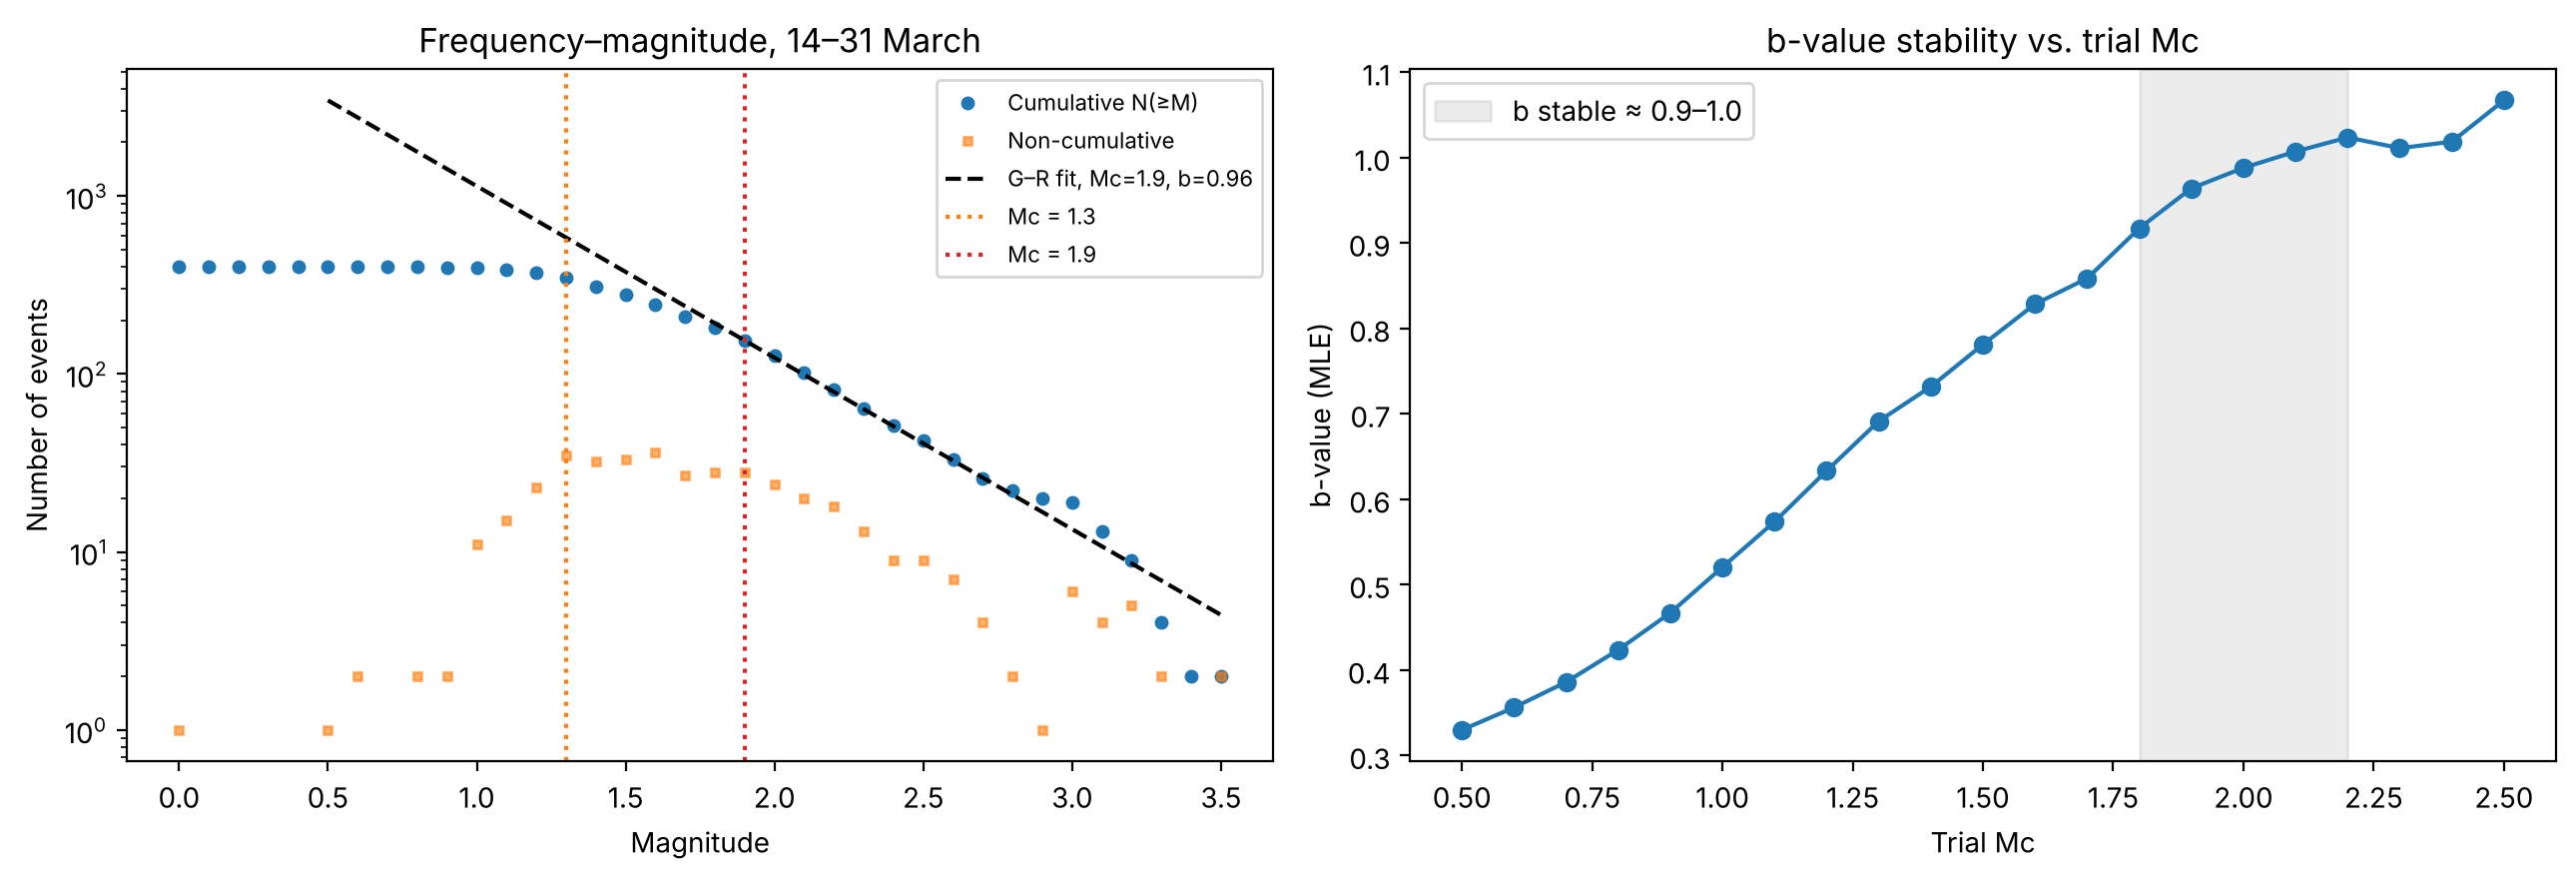

In [8]:
m_all = aft["mag"].values
g = gft_table(m_all)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

mags = np.round(np.arange(0, m_all.max() + DM, DM), 1)
cum = [(np.round(m_all, 1) >= x - 1e-9).sum() for x in mags]
non_cum = [(np.round(m_all, 1) == x).sum() for x in mags]
axes[0].semilogy(mags, cum, "o", ms=4, label="Cumulative N(≥M)")
axes[0].semilogy(mags, np.where(np.array(non_cum) > 0, non_cum, np.nan), "s", ms=3, alpha=.6, label="Non-cumulative")
MC_REF = 1.9
b_ref, n_ref = b_mle(m_all, MC_REF)
a_ref = np.log10(n_ref) + b_ref * MC_REF
xx = np.linspace(0.5, m_all.max(), 50)
axes[0].semilogy(xx, 10 ** (a_ref - b_ref * xx), "k--", label=f"G–R fit, Mc={MC_REF}, b={b_ref:.2f}")
for mc_line, c in [(1.3, "tab:orange"), (MC_REF, "tab:red")]:
    axes[0].axvline(mc_line, color=c, ls=":", label=f"Mc = {mc_line}")
axes[0].set(xlabel="Magnitude", ylabel="Number of events", title="Frequency–magnitude, 14–31 March")
axes[0].legend(fontsize=8)

axes[1].plot(g["Mc"], g["b"], "o-")
axes[1].set(xlabel="Trial Mc", ylabel="b-value (MLE)", title="b-value stability vs. trial Mc")
axes[1].axvspan(1.8, 2.2, color="grey", alpha=.15, label="b stable ≈ 0.9–1.0")
axes[1].legend()
plt.tight_layout(); plt.show()

**Reading the result**

* MAXC on the EDA window reproduces Mc = 1.3, but the corrected and goodness-of-fit estimates sit between 1.4 and 1.9, and the b-value only stabilises (≈ 0.9–1.0, typical for crustal sequences) once Mc ≥ 1.8.
* Mc is clearly **higher in the first 24 hours** than afterwards — the expected short-term incompleteness. A single Mc for 14–20 March mixes two regimes.
* A defensible working value for the whole 14–31 March sequence is **Mc ≈ 1.8–1.9**. After the first day the estimates fall to about 1.5–1.8; in the first 24 hours they are about 1.9–2.1.

### 2.1 How many events are probably missing?

Extrapolating the Gutenberg–Richter law below Mc gives the number of events the catalogue *should* contain if it were complete. The difference is the "prize" for a detector. b-value uncertainty dominates, so we bootstrap it.

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
above = m_all[m_all >= MC_REF - 1e-9]
boot = []
for _ in range(2000):
    sample = rng.choice(above, size=len(above), replace=True)
    b = np.log10(np.e) / (sample.mean() - (MC_REF - DM / 2))
    a = np.log10(len(above)) + b * MC_REF
    boot.append([10 ** (a - b * mmin) - (m_all >= mmin - 1e-9).sum() for mmin in (1.0, 1.5)])
boot = np.array(boot)
missing = pd.DataFrame({
    "M ≥": [1.0, 1.5],
    "observed": [(m_all >= 0.999).sum(), (m_all >= 1.499).sum()],
    "missing (median)": np.median(boot, axis=0).round(),
    "missing (5–95 %)": [f"{np.percentile(boot[:, i], 5):.0f} – {np.percentile(boot[:, i], 95):.0f}" for i in range(2)],
})
display(missing)

,M ≥,observed,missing (median),missing (5–95 %)
0,1.0,394,737.0,521 – 1062
1,1.5,278,96.0,62 – 140


Even with wide uncertainty, several hundred events of M ≥ 1.0 are probably missing from 14–31 March inside the study area. The 85 candidates accepted by visual review in the Modeling notebook are therefore entirely plausible — and they are a small fraction of what is likely there. This frames the result honestly: **the limiting factor is detector recall at small magnitudes, not a shortage of undetected events.**

## 3. Modelling table: one row per (event, station)

**Target** `picked` = 1 if the bulletin has a P-family pick (Pg, Pn, P) for that event at that station, else 0.

**Features** (all known *before* anyone picks the waveform):

| Feature | Why |
|---|---|
| `mag` | Bigger events are seen further away. |
| `station` (one-hot) | Each station has its own noise level, instrument and site. |
| `mag × station` | The magnitude effect can differ by station (interaction). |
| `log_hypo_km` | Geometric spreading and attenuation scale with log distance. |
| `log_hours` | Coda of earlier aftershocks masks later ones early in the sequence. |
| `night` | Cultural noise is lower at night (local time = UTC+1). |

**Leakage check (important):** `NST`, `GAP_deg`, `origin_time_sd_s`, `latitude_sd_deg`, `longitude_sd_deg` and `depth_sd_km` are computed *from* the picks we are trying to predict. Using them would leak the label. They are excluded.

**Label caveat:** "no pick" means the analyst did not pick that station. Usually the arrival was not visible, but an analyst may also skip a distant station once a location is stable. The model therefore learns *analyst-pickable* arrivals — exactly the right reference for an automatic detector that is evaluated against that bulletin.

In [10]:
# STATIONS (coordinates and elevations) was defined in section 1.4

p_picks = (picks[picks["phase"].isin(["Pg", "Pn", "P"])][["origin_utc", "station"]]
           .drop_duplicates().assign(picked=1))

events = aft[["origin_utc", "latitude_deg", "longitude_deg", "depth_km", "mag", "hours_since_main"]].copy()
events["event_id"] = np.arange(len(events))

df = events.merge(STATIONS, how="cross").merge(p_picks, on=["origin_utc", "station"], how="left")
df["picked"] = df["picked"].fillna(0).astype(int)
df["epi_km"] = haversine_km(df["latitude_deg"], df["longitude_deg"], df["st_lat"], df["st_lon"])
df["hypo_km"] = np.sqrt(df["epi_km"] ** 2 + (df["depth_km"] + df["st_elev_m"] / 1000) ** 2)
df["log_hypo_km"] = np.log10(df["hypo_km"])
df["log_hours"] = np.log10(df["hours_since_main"])
local_hour = (df["origin_utc"].dt.hour + 1) % 24
df["night"] = ((local_hour >= 22) | (local_hour < 6)).astype(int)
for st in STATIONS["station"]:
    df[f"mag_x_{st}"] = df["mag"] * (df["station"] == st)

print("Rows:", len(df), "| events:", df["event_id"].nunique())
print("Overall pick rate: %.3f  (minority class = missed arrival: %.1f %%)" % (df["picked"].mean(), 100 * (1 - df["picked"].mean())))
display(df.groupby("station").agg(pick_rate=("picked", "mean"), median_dist_km=("hypo_km", "median")).round(3)
          .sort_values("median_dist_km"))

Rows: 2814 | events: 402
Overall pick rate: 0.848  (minority class = missed arrival: 15.2 %)


,pick_rate,median_dist_km
station,,
BRY,0.988,20.096
UPM,0.848,35.594
NKME,0.948,36.841
CEME,0.973,54.745
HCY,0.731,62.843
KOME,0.721,73.080
DRME,0.724,99.516


The classes are imbalanced (about 15 % missed arrivals), so accuracy alone would be misleading — a model that always says "picked" is 85 % accurate. We report ROC-AUC, average precision for the **missed** class, the Brier score (probability quality) and balanced accuracy.

### 3.1 Splitting without leakage

Two rules:

1. **Group by event.** The seven rows of one event share its magnitude and timing. If some rows of an event are in training and others in testing, the model is partly tested on what it has already seen. We use `StratifiedGroupKFold` with `groups=event_id`.
2. **Respect time.** The final test is a **temporal hold-out**: train on 14–20 March, test on 21–31 March — the same logic as the fixed-parameter March test in the Modeling notebook.

In [11]:
SPLIT = pd.Timestamp("2024-03-21", tz="UTC")
train = df[df["origin_utc"] < SPLIT].reset_index(drop=True)
test = df[df["origin_utc"] >= SPLIT].reset_index(drop=True)
y_train, y_test = train["picked"], test["picked"]
groups = train["event_id"]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {train.event_id.nunique()} events ({len(train)} rows) | "
      f"Test: {test.event_id.nunique()} events ({len(test)} rows)")
print(f"Missed-arrival rate  train {1 - y_train.mean():.3f}  test {1 - y_test.mean():.3f}")

Train: 336 events (2352 rows) | Test: 66 events (462 rows)
Missed-arrival rate  train 0.140  test 0.214


## 4. Models

### 4.1 Baselines
Any model has to beat (a) the null model and (b) "each station's historical pick rate", which uses no event information at all.

In [12]:
def scores(y, p, name):
    return {"model": name,
            "ROC-AUC": roc_auc_score(y, p),
            "AP (missed class)": average_precision_score(1 - y, 1 - p),
            "Brier": brier_score_loss(y, p)}

results = []
null = DummyClassifier(strategy="prior").fit(train[["mag"]], y_train)
results.append(scores(y_test, null.predict_proba(test[["mag"]])[:, 1], "Null (prior)"))
station_rate = train.groupby("station")["picked"].mean()
results.append(scores(y_test, test["station"].map(station_rate), "Station pick rate"))
pd.DataFrame(results).round(3)

,model,ROC-AUC,AP (missed class),Brier
0,Null (prior),0.500,0.214,0.174
1,Station pick rate,0.739,0.341,0.154


### 4.2 Logistic regression — Pipeline + GridSearchCV with grouped CV

We compare feature sets and regularisation strength in one grid. `class_weight="balanced"` is included in the search for illustration, but note: **re-weighting distorts predicted probabilities**. Part 6 multiplies probabilities across stations, so calibrated probabilities matter more than a balanced threshold. We therefore choose the model by ROC-AUC and check calibration explicitly.

In [13]:
INTER = [f"mag_x_{s}" for s in STATIONS["station"]]
FEATURE_SETS = {
    "mag + station":                  (["mag"], ["station"]),
    "mag × station":                  (INTER, ["station"]),
    "mag × station + distance":       (INTER + ["log_hypo_km"], ["station"]),
    "mag × station + time + night":   (INTER + ["log_hours", "night"], ["station"]),
}

def make_logit(num, cat, C=1.0, cw=None):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("pre", pre), ("model", LogisticRegression(C=C, class_weight=cw, max_iter=5000))])

grid_rows = []
best = {}
for name, (num, cat) in FEATURE_SETS.items():
    gs = GridSearchCV(make_logit(num, cat),
                      {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
                      scoring="roc_auc", cv=cv, n_jobs=-1)
    gs.fit(train, y_train, groups=groups)
    best[name] = gs.best_estimator_
    grid_rows.append({"features": name, "best C": gs.best_params_["model__C"],
                      "class_weight": str(gs.best_params_["model__class_weight"]),
                      "CV ROC-AUC (train, grouped)": gs.best_score_})
pd.DataFrame(grid_rows).round(3)

,features,best C,class_weight,"CV ROC-AUC (train, grouped)"
0,mag + station,10,balanced,0.790
1,mag × station,10,balanced,0.801
2,mag × station + distance,10,balanced,0.801
3,mag × station + time + night,10,None,0.803


Adding distance barely helps, because aftershocks are clustered: each station sits at an almost constant distance, so the station dummy already carries that information (distance and station are close to collinear). Time-since-mainshock and night do not improve the grouped CV either. The simplest well-performing model is **magnitude × station**. We refit it with `class_weight=None` (calibrated probabilities) at the selected C.

In [14]:
C_best = [r["best C"] for r in grid_rows if r["features"] == "mag × station"][0]
logit = make_logit(*FEATURE_SETS["mag × station"], C=C_best, cw=None).fit(train, y_train)
p_logit = logit.predict_proba(test)[:, 1]
results.append(scores(y_test, p_logit, "Logistic: mag × station"))
print("Mean predicted pick probability on test: %.3f | observed pick rate: %.3f" % (p_logit.mean(), y_test.mean()))
pd.DataFrame(results).round(3)

Mean predicted pick probability on test: 0.863 | observed pick rate: 0.786


,model,ROC-AUC,AP (missed class),Brier
0,Null (prior),0.500,0.214,0.174
1,Station pick rate,0.739,0.341,0.154
2,Logistic: mag × station,0.804,0.527,0.144


### 4.3 Ensembles (random forest, gradient boosting)

Trees can find interactions and thresholds on their own. Same grouped CV, same temporal test.

In [15]:
TREE_FEATURES = ["mag", "log_hypo_km", "log_hours", "night"]
Xtr_tree = pd.get_dummies(train[TREE_FEATURES + ["station"]], columns=["station"])
Xte_tree = pd.get_dummies(test[TREE_FEATURES + ["station"]], columns=["station"]).reindex(columns=Xtr_tree.columns, fill_value=0)

rf_gs = GridSearchCV(RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
                     {"min_samples_leaf": [5, 10, 20], "max_features": ["sqrt", None]},
                     scoring="roc_auc", cv=cv, n_jobs=-1).fit(Xtr_tree, y_train, groups=groups)
hgb_gs = GridSearchCV(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                      {"max_depth": [2, 3], "learning_rate": [0.03, 0.1], "max_iter": [100, 300]},
                      scoring="roc_auc", cv=cv, n_jobs=-1).fit(Xtr_tree, y_train, groups=groups)
print("RF  best", rf_gs.best_params_, "CV AUC %.3f" % rf_gs.best_score_)
print("HGB best", hgb_gs.best_params_, "CV AUC %.3f" % hgb_gs.best_score_)

p_rf = rf_gs.predict_proba(Xte_tree)[:, 1]
p_hgb = hgb_gs.predict_proba(Xte_tree)[:, 1]
results.append(scores(y_test, p_rf, "Random forest"))
results.append(scores(y_test, p_hgb, "Gradient boosting (HGB)"))
summary = pd.DataFrame(results).round(3)
summary

RF  best {'max_features': 'sqrt', 'min_samples_leaf': 5} CV AUC 0.857
HGB best {'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 100} CV AUC 0.856


,model,ROC-AUC,AP (missed class),Brier
0,Null (prior),0.500,0.214,0.174
1,Station pick rate,0.739,0.341,0.154
2,Logistic: mag × station,0.804,0.527,0.144
3,Random forest,0.814,0.508,0.136
4,Gradient boosting (HGB),0.798,0.527,0.167


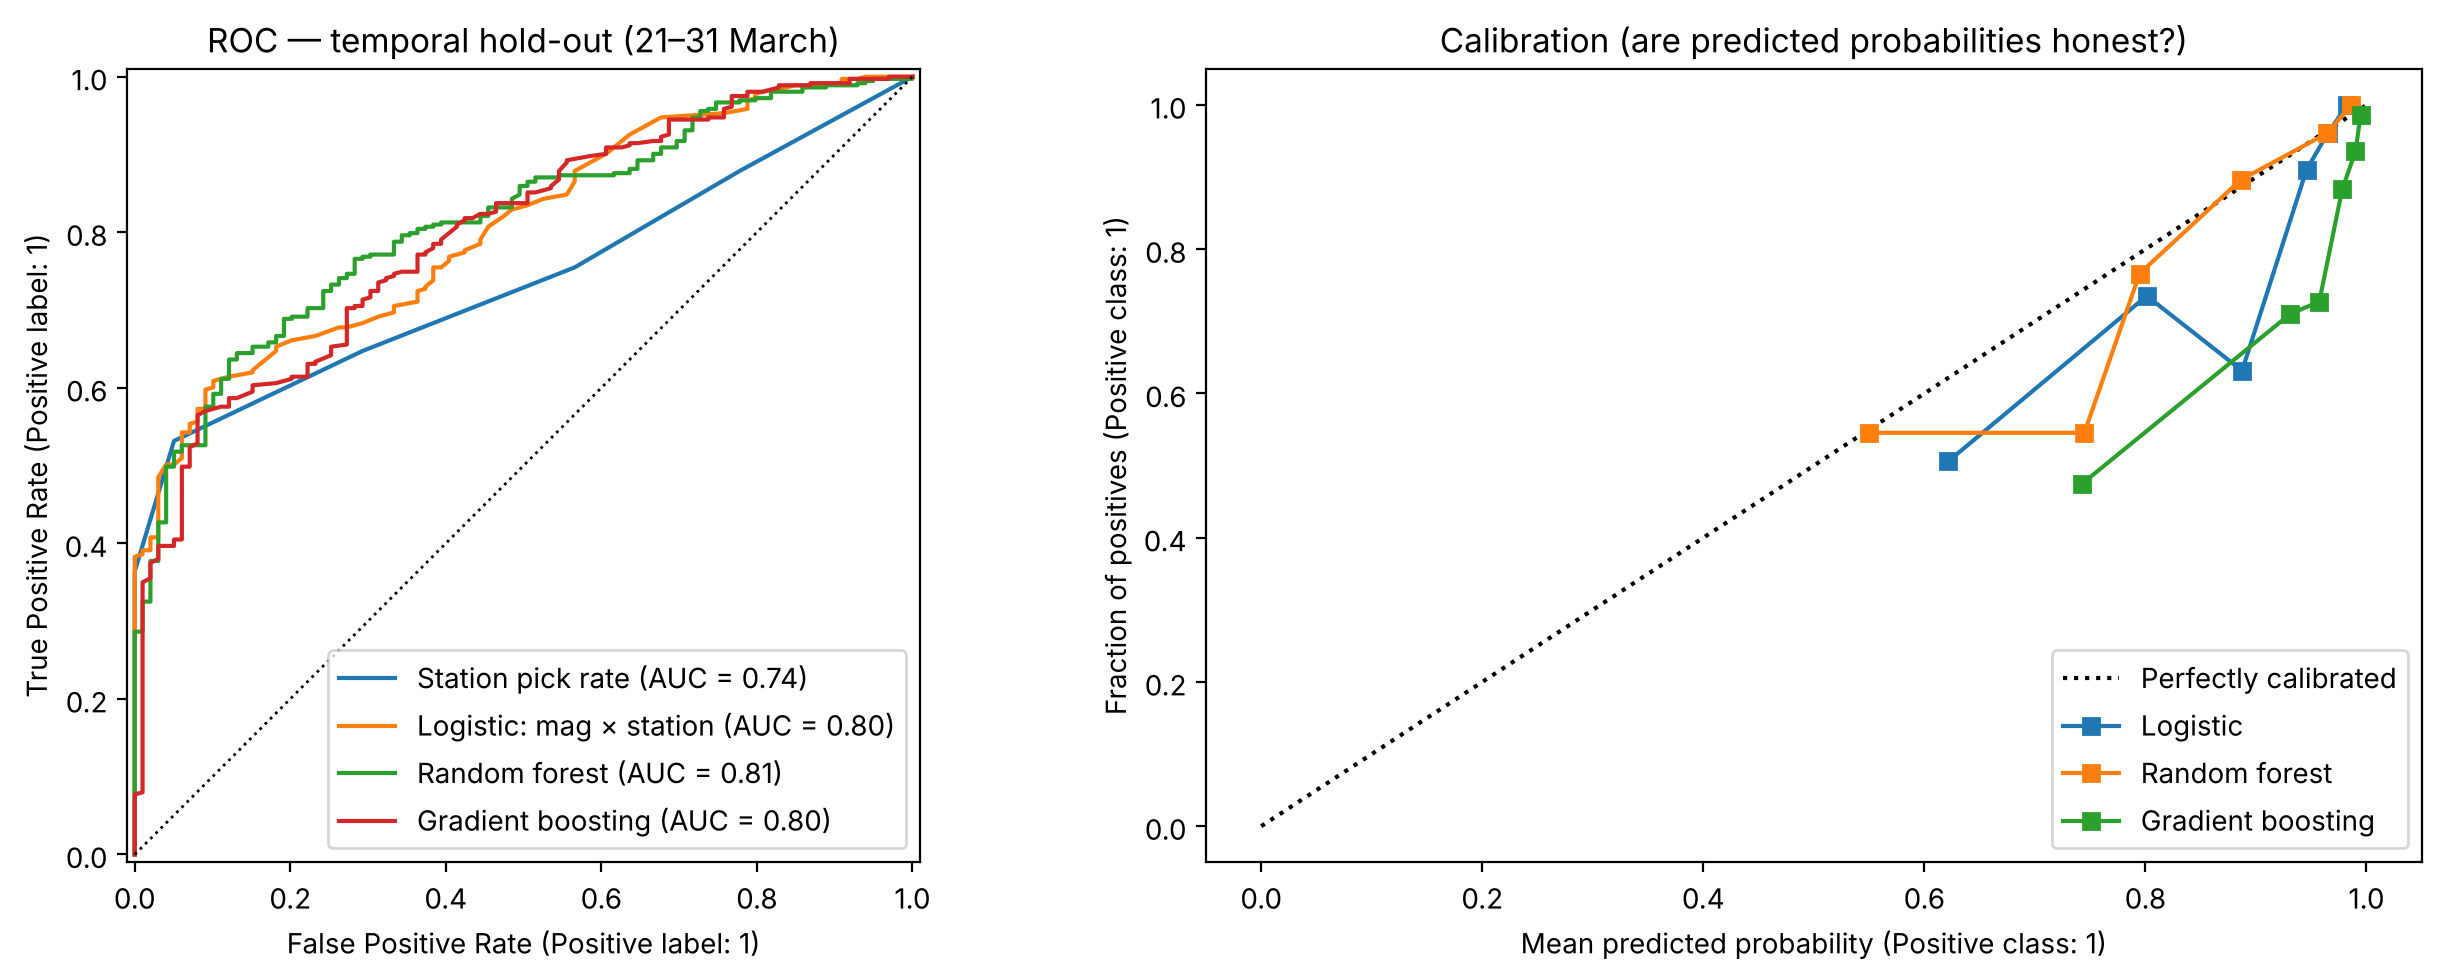

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for p, name in [(test["station"].map(station_rate), "Station pick rate"),
                (p_logit, "Logistic: mag × station"), (p_rf, "Random forest"), (p_hgb, "Gradient boosting")]:
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set_title("ROC — temporal hold-out (21–31 March)")
for p, name in [(p_logit, "Logistic"), (p_rf, "Random forest"), (p_hgb, "Gradient boosting")]:
    CalibrationDisplay.from_predictions(y_test, p, n_bins=6, strategy="quantile", name=name, ax=axes[1])
axes[1].set_title("Calibration (are predicted probabilities honest?)")
plt.tight_layout(); plt.show()

**Model choice.** The tree ensembles score higher in grouped cross-validation (≈ 0.86 vs ≈ 0.80) but not on the temporal hold-out, where all three models land at ≈ 0.80–0.81 ROC-AUC. Extra flexibility mostly learned patterns specific to 14–20 March that did not carry forward in time. All models beat the station-rate baseline, so magnitude adds real information.

The calibration plot shows every model predicting *more* picks than were made on 21–31 March: the missed-arrival rate rose from 14 % in training to 21 % in the test period. Part 6 shows why. We keep the **logistic model** for interpretation because it is transparent and gives one smooth detection curve per station.

### 4.4 From probabilities to decisions: threshold and confusion matrix

If the model were used to *flag* station–event pairs where an arrival is likely missing (for example, to tell an automatic picker where to look harder), the threshold should not be 0.5. Following the imbalanced-data lesson ("Option 4: change the class cutoff threshold"), we pick the threshold on **training** out-of-fold predictions to maximise balanced accuracy, then apply it unchanged to the test set.

Threshold chosen on training OOF predictions: 0.83


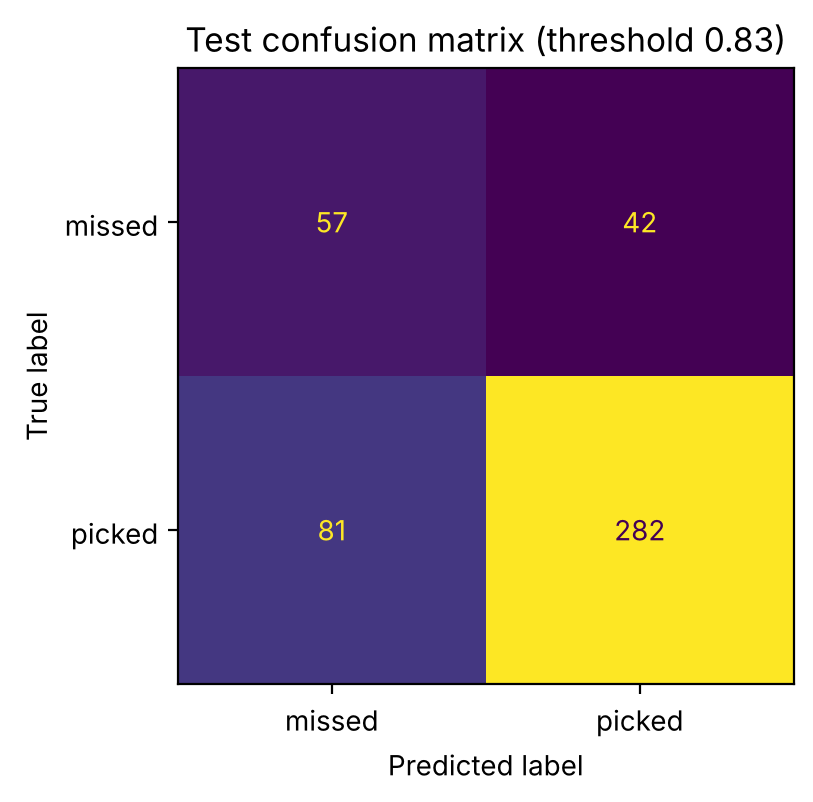

Balanced accuracy: 0.676 | recall of missed arrivals: 0.576 | precision of 'missed' flags: 0.413


In [17]:
oof = cross_val_predict(make_logit(*FEATURE_SETS["mag × station"], C=C_best), train, y_train,
                        groups=groups, cv=cv, method="predict_proba")[:, 1]
thresholds = np.linspace(0.5, 0.97, 48)
bal = [balanced_accuracy_score(y_train, (oof >= t).astype(int)) for t in thresholds]
t_star = thresholds[int(np.argmax(bal))]
print(f"Threshold chosen on training OOF predictions: {t_star:.2f}")

y_hat = (p_logit >= t_star).astype(int)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_hat, display_labels=["missed", "picked"], ax=ax, colorbar=False)
ax.set_title(f"Test confusion matrix (threshold {t_star:.2f})")
plt.show()
print("Balanced accuracy: %.3f | recall of missed arrivals: %.3f | precision of 'missed' flags: %.3f" % (
    balanced_accuracy_score(y_test, y_hat), recall_score(1 - y_test, 1 - y_hat), precision_score(1 - y_test, 1 - y_hat)))

## 5. Interpretation — detection curves per station

Logistic regression gives, for each station, $P(\text{picked} \mid M) = \sigma(\beta_{0,s} + \beta_{1,s} M)$. The magnitude at which the probability reaches 50 % or 90 % is a station's **detection threshold** — the quantity a seismologist would call the station's completeness magnitude for this source zone.

,M50,M90,median_hypo_km
station,,,
BRY,≤ 0.5,≤ 0.5,20.1
UPM,≤ 0.5,≤ 0.5,35.6
NKME,≤ 0.5,≤ 0.5,36.8
CEME,≤ 0.5,≤ 0.5,54.7
HCY,0.75,2.75,62.8
KOME,1.10,2.20,73.1
DRME,1.20,2.15,99.5


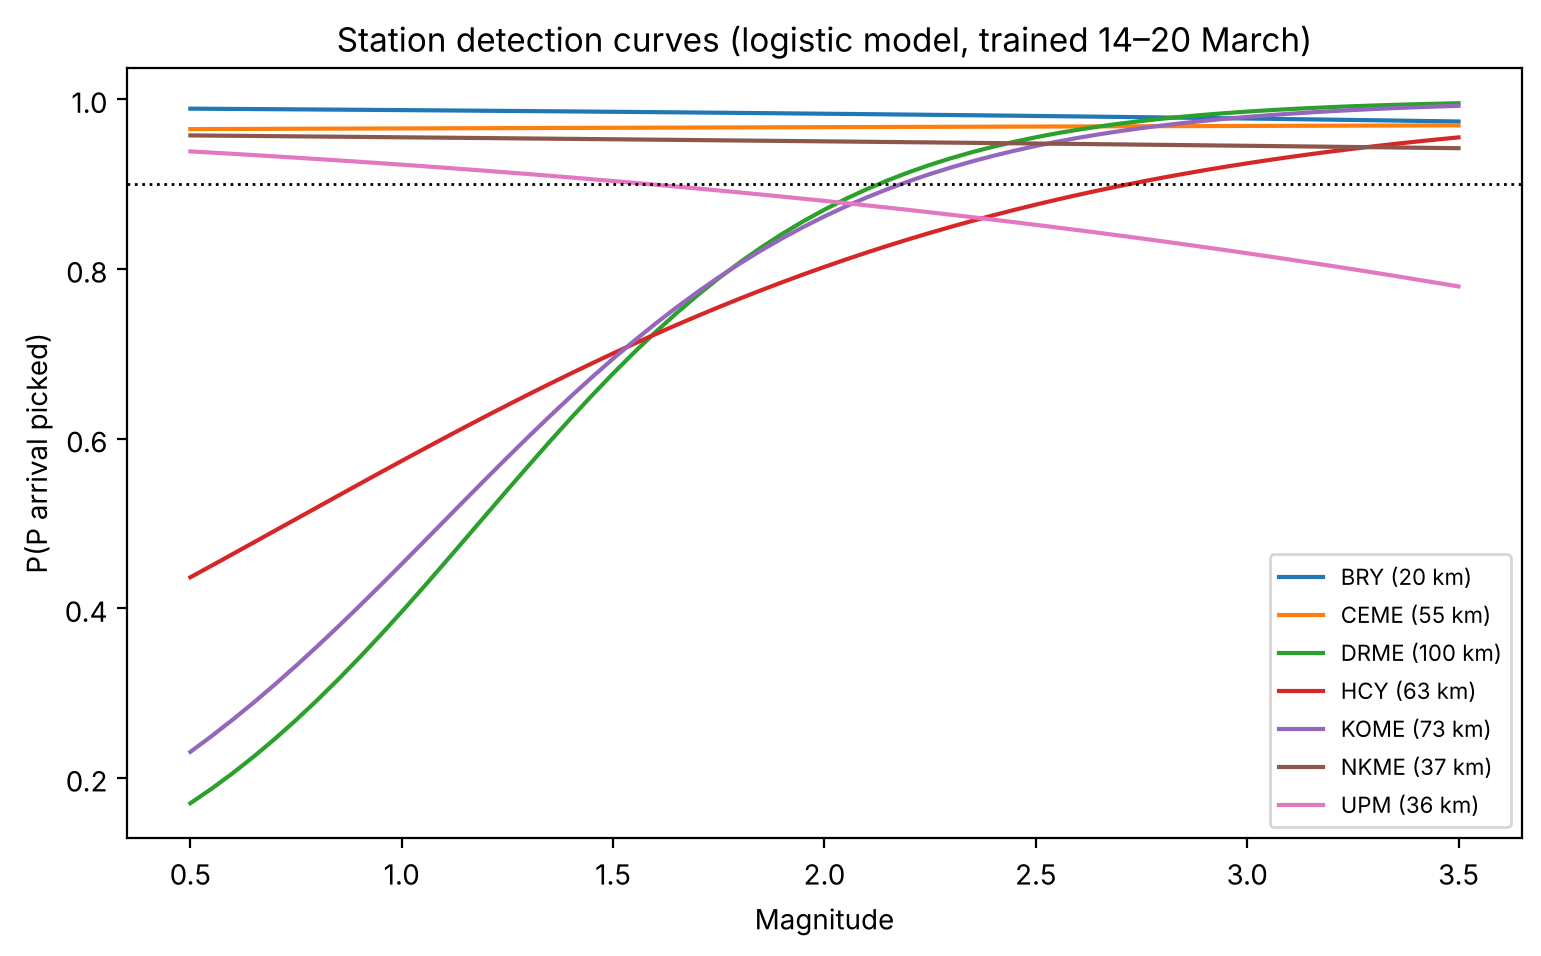

In [18]:
grid_m = np.round(np.arange(0.5, 3.51, 0.05), 2)   # 0.5 = smallest catalogue magnitude in the window
curves = []
for st in STATIONS["station"]:
    tmp = pd.DataFrame({"mag": grid_m, "station": st})
    for s2 in STATIONS["station"]:
        tmp[f"mag_x_{s2}"] = tmp["mag"] * (st == s2)
    tmp["p"] = logit.predict_proba(tmp)[:, 1]
    curves.append(tmp[["mag", "station", "p"]])
curves = pd.concat(curves)

def first_mag(c, level):
    hit = c[c["p"] >= level]
    if hit.empty:
        return "> 3.5"
    m = hit["mag"].min()
    return "≤ 0.5" if m <= 0.5 else f"{m:.2f}"

dist_by_station = df.groupby("station")["hypo_km"].median()
thr = (curves.groupby("station")
       .apply(lambda c: pd.Series({"M50": first_mag(c, 0.5), "M90": first_mag(c, 0.9)}), include_groups=False)
       .join(dist_by_station.rename("median_hypo_km").round(1))
       .sort_values("median_hypo_km"))
display(thr)

fig, ax = plt.subplots(figsize=(9, 5))
for st, c in curves.groupby("station"):
    ax.plot(c["mag"], c["p"], label=f"{st} ({dist_by_station[st]:.0f} km)")
ax.axhline(0.9, color="k", ls=":", lw=1)
ax.set(xlabel="Magnitude", ylabel="P(P arrival picked)", title="Station detection curves (logistic model, trained 14–20 March)")
ax.legend(fontsize=8); plt.show()

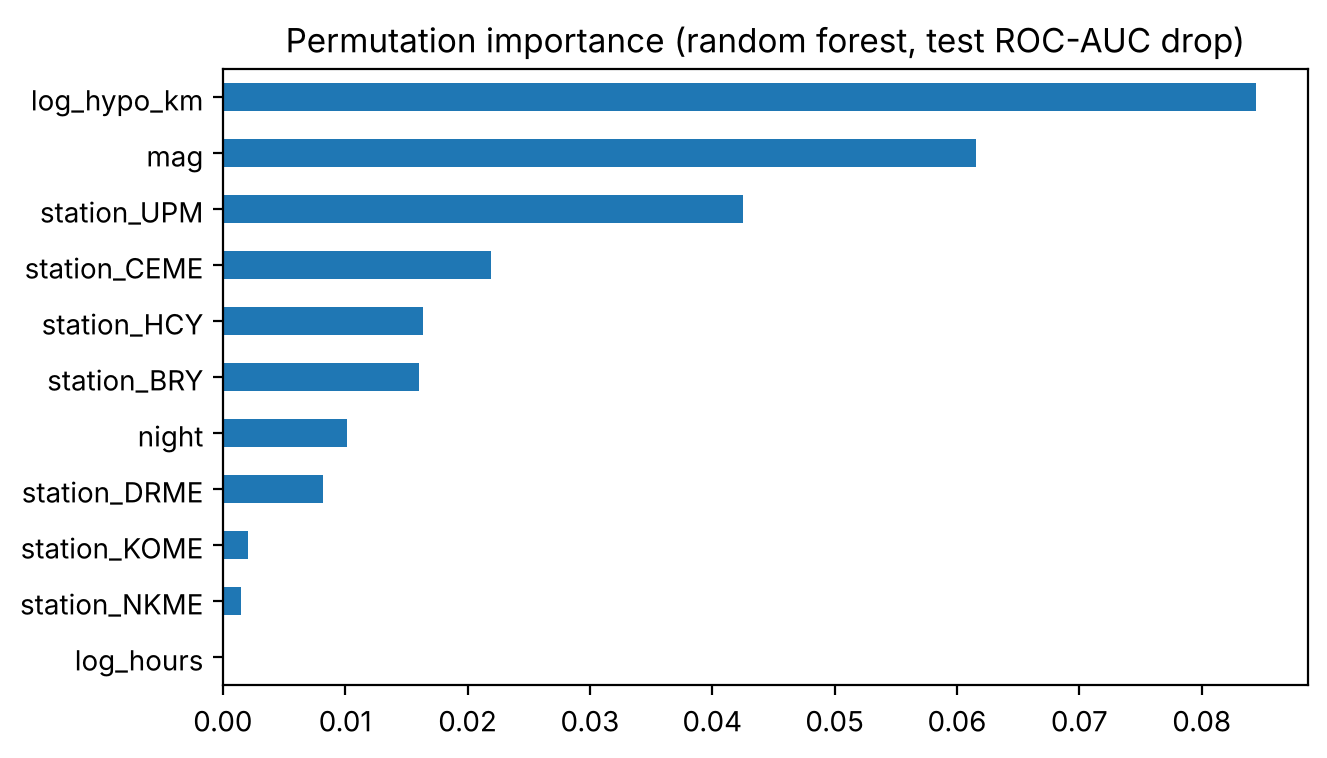

log_hypo_km     0.084
mag             0.062
station_UPM     0.042
station_CEME    0.022
station_HCY     0.016
station_BRY     0.016
night           0.010
station_DRME    0.008
station_KOME    0.002
station_NKME    0.001
log_hours       0.000


In [19]:
perm = permutation_importance(rf_gs.best_estimator_, Xte_tree, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(perm.importances_mean, index=Xte_tree.columns).sort_values()
imp.plot.barh(figsize=(7, 4), title="Permutation importance (random forest, test ROC-AUC drop)")
plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

Two groups emerge. **BRY, CEME, NKME and UPM** pick nearly every catalogued aftershock, so magnitude barely matters there (their M50 and M90 sit below the smallest catalogued magnitude). Their slightly *negative* fitted slopes are not physics: the largest aftershocks cluster in the first hours, when overlapping codas cause occasional misses. **DRME, HCY and KOME** behave like classic detection curves, reaching 90 % only around M 2.2–2.8.

In the random forest, distance and magnitude carry most of the predictive weight, followed by the station identities; time since the mainshock adds nothing and night very little.

## 6. Network level: how many stations can a detector expect?

### 6.1 First attempt — combine the station probabilities

If station detections were independent *given magnitude*, the number of stations $N$ that pick an event would follow a **Poisson-binomial** distribution of the seven station probabilities, and $P(N \ge 5)$ would follow directly. This is a modelling assumption, so we test it before using it.

In [20]:
def poisson_binomial(ps):
    dist = np.array([1.0])
    for p in ps:
        dist = np.convolve(dist, [1 - p, p])
    return dist  # dist[n] = P(N = n)

# Out-of-fold station probabilities for ALL events (grouped CV): every event is scored by a model that never saw it
oof_all = cross_val_predict(make_logit(*FEATURE_SETS["mag × station"], C=C_best), df, df["picked"],
                            groups=df["event_id"], cv=cv, method="predict_proba")[:, 1]
ev_net = (df.assign(p=oof_all)
            .groupby("event_id")
            .agg(origin_utc=("origin_utc", "first"), mag=("mag", "first"),
                 n_obs=("picked", "sum"), ps=("p", list)))
ev_net["pred_dist"] = ev_net["ps"].apply(poisson_binomial)

dist_check = pd.DataFrame({
    "predicted share": np.mean(np.vstack(ev_net["pred_dist"]), axis=0),
    "observed share": np.bincount(ev_net["n_obs"], minlength=8) / len(ev_net),
}).rename_axis("stations with a P pick")
display(dist_check.round(3))
print("Mean stations per event — predicted %.2f, observed %.2f" % (
    (np.vstack(ev_net["pred_dist"]) @ np.arange(8)).mean(), ev_net["n_obs"].mean()))

,predicted share,observed share
stations with a P pick,,
0,0.000,0.000
1,0.000,0.002
2,0.001,0.005
3,0.010,0.060
4,0.071,0.117
5,0.218,0.127
6,0.377,0.184
7,0.324,0.505


Mean stations per event — predicted 5.93, observed 5.93


The model gets the *average* number of stations about right but the *spread* wrong: many more events are picked at all seven stations, and many more at four or fewer, than independence predicts. Station misses are **correlated** — a noisy hour, an overlapping aftershock, or an analyst decision affects several stations at once. Multiplying station probabilities would therefore give a misleading network detection curve.

### 6.2 Is the reference stable over time?

In [21]:
period_edges = pd.to_datetime(["2024-03-14", "2024-03-15", "2024-03-18", "2024-03-21", "2024-04-01"], utc=True)
period_labels = ["14 Mar", "15–17 Mar", "18–20 Mar", "21–31 Mar"]
df["period"] = pd.cut(df["origin_utc"], bins=period_edges, labels=period_labels, right=False)
ev_net["period"] = pd.cut(ev_net["origin_utc"], bins=period_edges, labels=period_labels, right=False)

display(df.pivot_table(index="station", columns="period", values="picked", aggfunc="mean", observed=True).round(2))
ev_net["p_ge5"] = ev_net["pred_dist"].apply(lambda d: d[5:].sum())
ev_net["obs_ge5"] = (ev_net["n_obs"] >= 5).astype(int)
display(ev_net.groupby("period", observed=True)
              .agg(events=("mag", "size"), mean_mag=("mag", "mean"),
                   predicted_share_ge5=("p_ge5", "mean"), observed_share_ge5=("obs_ge5", "mean"))
              .round(2))

period,14 Mar,15–17 Mar,18–20 Mar,21–31 Mar
station,,,,
BRY,0.97,0.99,1.00,1.00
CEME,0.95,0.97,0.99,1.00
DRME,0.82,0.86,0.36,0.67
HCY,0.77,0.80,0.58,0.68
KOME,0.84,0.83,0.42,0.59
NKME,0.89,1.00,0.97,0.92
UPM,0.83,0.98,0.82,0.64


,events,mean_mag,predicted_share_ge5,observed_share_ge5
period,,,,
14 Mar,130,2.01,0.95,0.87
15–17 Mar,133,1.68,0.91,0.92
18–20 Mar,73,1.46,0.88,0.66
21–31 Mar,66,1.77,0.92,0.68


From 18 March the three distant stations (DRME, HCY, KOME), and later UPM, are picked much less often at similar magnitudes. Either those stations became noisier or the analysts stopped picking distant stations routinely once the sequence calmed down. A model trained on earlier days cannot anticipate this, which explains the over-prediction on the hold-out.

This is an **EDA finding about the reference itself**, and it matters for the capstone evaluation. If the distant stations were genuinely less usable after 18 March, a ≥ 5-station detector will lose recall in the later blocks — the same direction as the Modeling notebook's temporal validation (16.7 % → 20.0 % → 0 %). Station state-of-health and the analysts' picking practice for those days are worth checking.

### 6.3 What the analysts' picks say directly: a recall benchmark

Because the modelled route is limited by correlation and drift, we finish with the empirical quantity the capstone needs: for each reference event, how many of the seven stations have an analyst P pick? This is a **benchmark rather than a hard ceiling**: an automatic picker can find arrivals that an analyst chose not to pick, and it can also miss arrivals an analyst saw. It tells us what recall a ≥ k-station rule should reach if the automatic picks were as good as the analysts'.

In [22]:
ref = ev_net[ev_net["origin_utc"] >= "2024-03-15"]
ceiling = pd.DataFrame({
    "rule": [f"≥{k} stations" for k in range(3, 8)],
    "events with ≥k analyst P picks": [(ref["n_obs"] >= k).sum() for k in range(3, 8)],
    "recall benchmark (15–31 Mar)": [(ref["n_obs"] >= k).mean() for k in range(3, 8)],
})
print("Reference events 15–31 March:", len(ref))
display(ceiling.round(3))

# Ceiling for the Modeling notebook's three validation blocks, next to the recall it achieved there
blocks = [("19–22 Mar", "2024-03-19", "2024-03-23", 12 / 72), ("23–26 Mar", "2024-03-23", "2024-03-27", 5 / 25),
          ("27–31 Mar", "2024-03-27", "2024-04-01", 0 / 10)]
rows = []
for name, a, b, achieved in blocks:
    in_block = (ev_net["origin_utc"] >= pd.Timestamp(a, tz="UTC")) & (ev_net["origin_utc"] < pd.Timestamp(b, tz="UTC"))
    rows.append({"validation block": name, "reference events": int(in_block.sum()),
                 "≥5-station benchmark": (ev_net.loc[in_block, "n_obs"] >= 5).mean(),
                 "recall achieved (Modeling nb)": achieved})
display(pd.DataFrame(rows).round(3))

Reference events 15–31 March: 272


,rule,events with ≥k analyst P picks,recall benchmark (15–31 Mar)
0,≥3 stations,272,1.000
1,≥4 stations,253,0.930
2,≥5 stations,215,0.790
3,≥6 stations,179,0.658
4,≥7 stations,132,0.485


,validation block,reference events,≥5-station benchmark,recall achieved (Modeling nb)
0,19–22 Mar,72,0.694,0.167
1,23–26 Mar,25,0.600,0.200
2,27–31 Mar,10,0.800,0.000


mean                size          
regime      14–17 Mar 18–31 Mar 14–17 Mar 18–31 Mar
mag_bin                                            
(0.0, 1.0]       0.83      0.25         6        12
(1.0, 1.25]      0.70      0.78        20        18
(1.25, 1.5]      0.89      0.53        64        36
(1.5, 1.75]      0.92      0.83        40        23
(1.75, 2.0]      0.93      0.68        55        25
(2.0, 2.5]       0.88      0.89        51        18
(2.5, 6.0]       0.96      0.83        27         6

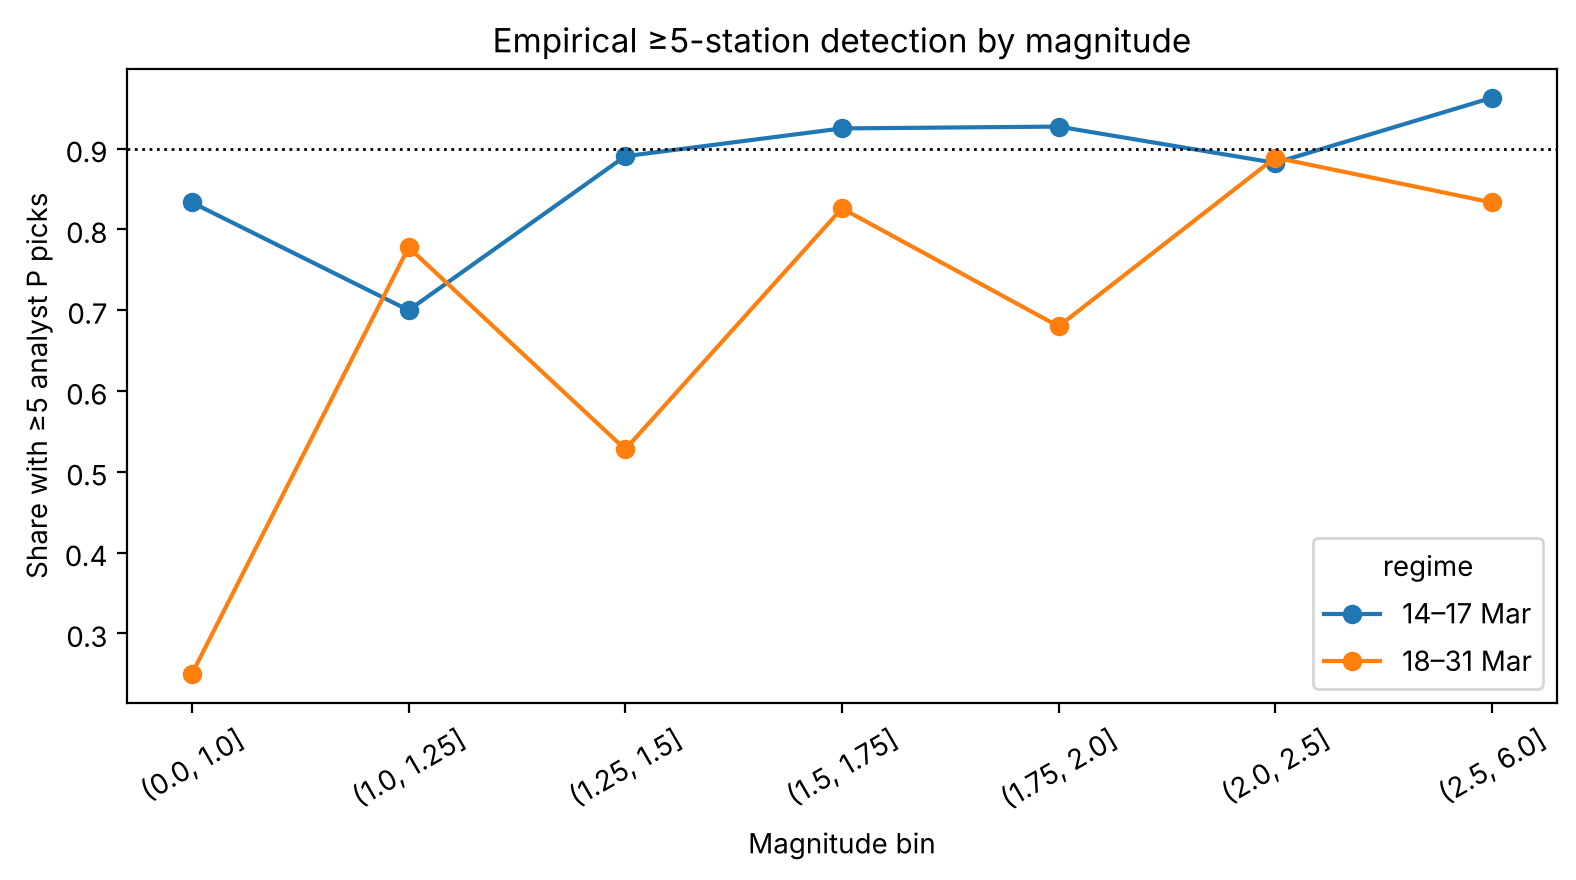

In [23]:
# Empirical network detection curve: share of events with ≥5 analyst P picks by magnitude, before/after 18 March
ev_net["mag_bin"] = pd.cut(ev_net["mag"], [0, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 6])
ev_net["regime"] = np.where(ev_net["origin_utc"] < pd.Timestamp("2024-03-18", tz="UTC"), "14–17 Mar", "18–31 Mar")
curve = (ev_net.groupby(["mag_bin", "regime"], observed=True)["obs_ge5"]
               .agg(["mean", "size"]).unstack("regime"))
display(curve.round(2))

ax = curve["mean"].plot(marker="o", figsize=(8, 4.5))
ax.axhline(0.9, color="k", ls=":", lw=1)
ax.set_xticks(range(len(curve)))
ax.set_xticklabels([str(i) for i in curve.index], rotation=30)
ax.set(xlabel="Magnitude bin", ylabel="Share with ≥5 analyst P picks",
       title="Empirical ≥5-station detection by magnitude")
plt.tight_layout(); plt.show()

**What this tells us about the capstone's detector**

* 79 % of the 272 reference events in 15–31 March have analyst P picks at five or more of the seven stations. The fixed workflow recovered 21 %. **The ≥ 5-station rule is not what limits recall**; the gap is in picking, association and the location filter (Part 7 separates these).
* Before 18 March, events of M ≥ 1.25 reach five analyst-picked stations close to 90 % of the time. After 18 March that share is lower at the same magnitudes, so recall should be reported per period rather than as one number for the month.
* Caveat on selection: every row here is a catalogued event. The catalogue is built from a wider network (median NST of 26 per solution), so being catalogued does not require these seven stations, but detection rates below M 1 are probably still optimistic.

## 7. Where are the events lost?

The Modeling pipeline has four stages: (1) MAD picks per station, (2) association across stations, (3) least-squares location with depth bounded to 0–33 km, and (4) final filters (≥ 5 stations, RMS ≤ 0.8 s, **no search-boundary flag**, inside 30 km). Recall fell to 21 %, but the notebooks never show which stage caused the loss.

The bulletin lets us isolate stage 3–4. We feed the **analysts' P picks** (stage 1–2 done perfectly) into a re-implementation of the capstone locator — same local projection, same 6.03 km/s, same bounds, and the same rule that `search_boundary = True` whenever any bound is active — and ask how many of the 272 reference events would survive the final filters. One difference: the capstone starts each fit at a trial catalogue hypocentre; here every fit starts at the study centre at 10 km, so no catalogue location is used.

### 7.1 The capstone locator with perfect picks: free depth vs fixed depth

In [24]:
from scipy.optimize import least_squares

st_geo = STATIONS.set_index("station").copy()
lat_c, lon_c = st_geo["st_lat"].mean(), st_geo["st_lon"].mean()          # projection centre, as in the Modeling notebook
KM_LAT = 111.195
KM_LON = KM_LAT * np.cos(np.radians(lat_c))
st_geo["x"] = (st_geo["st_lon"] - lon_c) * KM_LON
st_geo["y"] = (st_geo["st_lat"] - lat_c) * KM_LAT
XY_LO = [st_geo["x"].min() - 50, st_geo["y"].min() - 50]
XY_HI = [st_geo["x"].max() + 50, st_geo["y"].max() + 50]
START = ((LON0 - lon_c) * KM_LON, (LAT0 - lat_c) * KM_LAT)

def locate(event_picks, fixed_depth=None, vp=VP):
    # P-only location with a constant velocity. fixed_depth=None reproduces the capstone (depth bounded 0-33 km).
    g = st_geo.loc[event_picks["station"]]
    t0 = event_picks["arrival_utc"].min()
    obs = (event_picks["arrival_utc"] - t0).dt.total_seconds().to_numpy()
    def predicted(x, y, z, t):
        return t + np.sqrt((g["x"].values - x) ** 2 + (g["y"].values - y) ** 2
                           + (z + g["st_elev_m"].values / 1000) ** 2) / vp
    if fixed_depth is None:
        fit = least_squares(lambda p: obs - predicted(*p), [*START, 10.0, -5.0],
                            bounds=(XY_LO + [0.0, -np.inf], XY_HI + [33.0, np.inf]), x_scale="jac")
        x, y, z, t = fit.x
    else:
        fit = least_squares(lambda p: obs - predicted(p[0], p[1], fixed_depth, p[2]), [*START, -5.0],
                            bounds=(XY_LO + [-np.inf], XY_HI + [np.inf]), x_scale="jac")
        (x, y, t), z = fit.x, fixed_depth
    resid = obs - predicted(x, y, z, t)
    return {"lat": lat_c + y / KM_LAT, "lon": lon_c + x / KM_LON, "depth": z, "stations": len(event_picks),
            "rms_s": np.sqrt(np.mean(resid ** 2)), "search_boundary": bool(np.any(fit.active_mask != 0)),
            "origin_est": t0 + pd.to_timedelta(t, unit="s")}

def run_locator(obs_table, **kw):
    rows = []
    for origin, ev in obs_table.groupby("origin_utc"):
        if len(ev) < 4:                      # the capstone needs ≥ 4 picks to start a location
            continue
        r = locate(ev, **kw)
        r.update(origin_utc=origin, cat_lat=ev["latitude_deg"].iloc[0], cat_lon=ev["longitude_deg"].iloc[0])
        rows.append(r)
    out = pd.DataFrame(rows)
    out["epi_err_km"] = haversine_km(out["lat"], out["lon"], out["cat_lat"], out["cat_lon"])
    out["origin_err_s"] = (out["origin_est"] - out["origin_utc"]).dt.total_seconds()
    out["dist_centre_km"] = haversine_km(LAT0, LON0, out["lat"], out["lon"])
    base = (out["stations"] >= 5) & (out["rms_s"] <= 0.80) & (out["dist_centre_km"] <= RADIUS_KM)
    out["passes_capstone_filters"] = base & ~out["search_boundary"]
    out["passes_without_boundary_rule"] = base
    return out

TEST_FROM = pd.Timestamp("2024-03-15", tz="UTC")
N_REF = int((after_main["origin_utc"] >= TEST_FROM).sum())   # 272

def summarise(loc, label):
    t = loc[loc["origin_utc"] >= TEST_FROM]
    return {"setting": label,
            "depth at a bound": t["search_boundary"].mean(),
            "median epicentre error (km)": t["epi_err_km"].median(),
            "90th pct epicentre error (km)": t["epi_err_km"].quantile(0.9),
            "median |origin error| (s)": t["origin_err_s"].abs().median(),
            "share of 272 passing capstone filters": t["passes_capstone_filters"].sum() / N_REF,
            "share passing without boundary rule": t["passes_without_boundary_rule"].sum() / N_REF}

loc_free = run_locator(p_obs)
rows = [summarise(loc_free, "free depth 0–33 km (capstone)")]
for z in (8, 13):
    rows.append(summarise(run_locator(p_obs, fixed_depth=z), f"depth fixed at {z} km"))
perfect = pd.DataFrame(rows).set_index("setting")
display(perfect.round(2))
print("Catalogue median depth, 14–31 March: %.1f km" % after_main["depth_km"].median())

,depth at a bound,median epicentre error (km),90th pct epicentre error (km),median |origin error| (s),share of 272 passing capstone filters,share passing without boundary rule
setting,,,,,,
free depth 0–33 km (capstone),0.18,2.18,5.82,0.35,0.66,0.77
depth fixed at 8 km,0.00,2.45,5.04,0.47,0.77,0.77
depth fixed at 13 km,0.00,1.57,4.10,0.23,0.77,0.77


Catalogue median depth, 14–31 March: 13.5 km


Even with the analysts' own picks, the free-depth locator pushes about one real event in five to a depth bound (almost always 0 km), and the boundary rule then throws it away: the share of the 272 reference events that survive drops from about 77 % to about 66 %. Fixing depth removes the boundary problem entirely and also gives the **smallest** epicentre and origin-time errors (fixed at 13 km ≈ the catalogue median depth). With perfect picks, about **77 %** of the reference events would pass the remaining filters — close to the 79 % benchmark from 6.3.

### 7.2 What happens with realistic pick errors?

The MAD picker's median absolute error on CEME was 0.435 s, which corresponds to a Gaussian σ of roughly 0.65 s. We add random errors of that size to the analysts' picks and repeat. (This keeps every pick, so it isolates the effect of timing error; real MAD picks also miss stations and include spurious triggers.)

In [25]:
rng = np.random.default_rng(RANDOM_STATE)
rows = []
for sigma in (0.3, 0.65):
    noisy = p_obs.copy()
    noisy["arrival_utc"] = noisy["arrival_utc"] + pd.to_timedelta(rng.normal(0, sigma, len(noisy)), unit="s")
    rows.append(summarise(run_locator(noisy), f"σ = {sigma} s, free depth (capstone)"))
    rows.append(summarise(run_locator(noisy, fixed_depth=13), f"σ = {sigma} s, depth fixed at 13 km"))
noisy_table = pd.DataFrame(rows).set_index("setting")
display(noisy_table.round(2))

,depth at a bound,median epicentre error (km),90th pct epicentre error (km),median |origin error| (s),share of 272 passing capstone filters,share passing without boundary rule
setting,,,,,,
"σ = 0.3 s, free depth (capstone)",0.27,3.18,7.53,0.52,0.59,0.77
"σ = 0.3 s, depth fixed at 13 km",0.00,2.74,5.15,0.27,0.76,0.76
"σ = 0.65 s, free depth (capstone)",0.46,4.85,12.21,0.74,0.45,0.74
"σ = 0.65 s, depth fixed at 13 km",0.01,3.91,8.43,0.37,0.70,0.70


With pick errors of the size measured on CEME, **almost half of the real events end at a depth bound**, and the boundary rule cuts the surviving share to about 45 %, against about 70 % when depth is fixed. The median epicentre error in this simulation (≈ 5 km) is close to the 4.4 km measured on the 58 matched pairs in the capstone, which suggests the simulation is realistic.

So a depth at a bound is the **normal** outcome of a P-only, free-depth fit on this network with automatic picks. It says nothing about whether the detection is real.

### 7.3 The development-day evidence says the same

The 14 March table in the Modeling notebook (cell "Location assessment of time-matched events") reports candidates and ±2 s catalogue matches by station count and `search_boundary`. The numbers are copied from that output (130 reference aftershocks).

,stations,search_boundary,candidates,time_matches,median_epicentral_error_km
0,4,False,138,3,7.725
1,4,True,377,4,5.705
2,5,False,65,8,13.875
3,5,True,113,16,5.232
4,6,False,40,13,6.548
5,6,True,58,20,2.168
6,7,False,8,7,2.222
7,7,True,34,23,1.647


,rule,boundary solutions,candidates,matches,catalogue precision,recall (of 130)
0,≥4 stations,removed,251,31,0.124,0.238
1,≥4 stations,kept,833,94,0.113,0.723
2,≥5 stations,removed,113,28,0.248,0.215
3,≥5 stations,kept,318,87,0.274,0.669
4,≥6 stations,removed,48,20,0.417,0.154
5,≥6 stations,kept,140,63,0.450,0.485
6,≥7 stations,removed,8,7,0.875,0.054
7,≥7 stations,kept,42,30,0.714,0.231


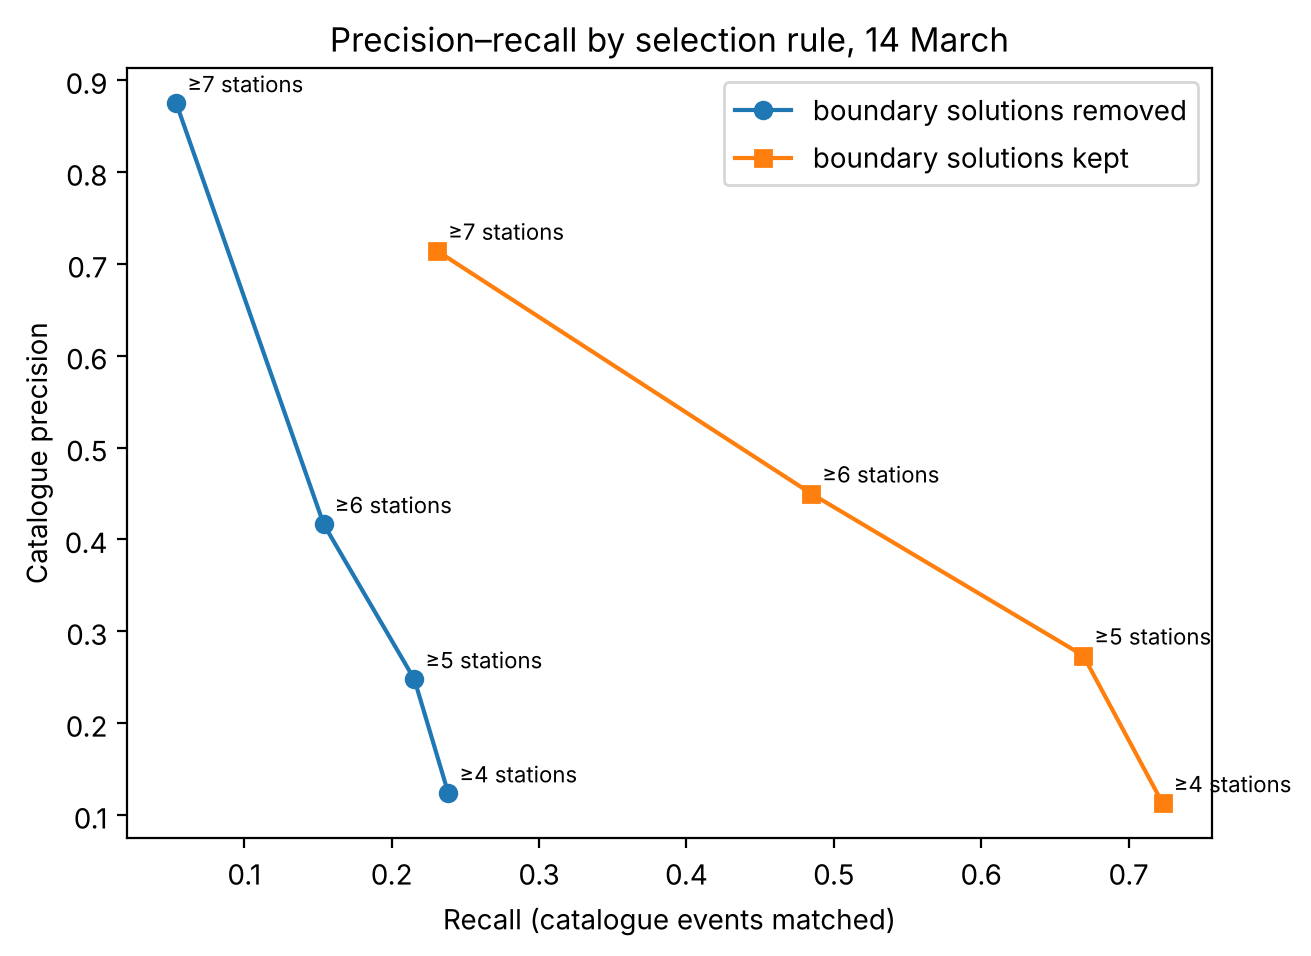

113 candidates: expected chance matches among 130 events ≈ 0.8
318 candidates: expected chance matches among 130 events ≈ 2.2


In [26]:
dev_day = pd.DataFrame({
    "stations":        [4, 4, 5, 5, 6, 6, 7, 7],
    "search_boundary": [False, True] * 4,
    "candidates":      [138, 377, 65, 113, 40, 58, 8, 34],
    "time_matches":    [3, 4, 8, 16, 13, 20, 7, 23],
    "median_epicentral_error_km": [7.725, 5.705, 13.875, 5.232, 6.548, 2.168, 2.222, 1.647],
})
display(dev_day)

rows = []
for k in (4, 5, 6, 7):
    for keep_boundary in (False, True):
        sel = dev_day[(dev_day["stations"] >= k) & (keep_boundary | ~dev_day["search_boundary"])]
        tp, n = sel["time_matches"].sum(), sel["candidates"].sum()
        rows.append({"rule": f"≥{k} stations", "boundary solutions": "kept" if keep_boundary else "removed",
                     "candidates": n, "matches": tp,
                     "catalogue precision": tp / n, "recall (of 130)": tp / 130})
rules = pd.DataFrame(rows)
display(rules.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
for b, mk in [("removed", "o"), ("kept", "s")]:
    r = rules[rules["boundary solutions"] == b]
    ax.plot(r["recall (of 130)"], r["catalogue precision"], marker=mk, label=f"boundary solutions {b}")
    for _, row in r.iterrows():
        ax.annotate(row["rule"], (row["recall (of 130)"], row["catalogue precision"]), fontsize=8,
                    xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="Recall (catalogue events matched)", ylabel="Catalogue precision",
       title="Precision–recall by selection rule, 14 March")
ax.legend(); plt.show()

# Could the ±2 s matches be coincidences? Expected chance matches if candidates were random in time.
seconds_after_main = (pd.Timestamp("2024-03-15", tz="UTC") - MAINSHOCK_UTC).total_seconds()
for n_cand in (113, 318):
    print(f"{n_cand} candidates: expected chance matches among 130 events ≈ {130 * n_cand / seconds_after_main * 4:.1f}")

**Reading Part 7 as a whole**

* At ≥ 5 stations on 14 March, removing boundary solutions keeps 28 of 130 matches (recall 22 %); keeping them gives 87 (recall 67 %) at **the same catalogue precision** (about 25–27 %). Boundary solutions with 6–7 stations have the *smallest* epicentre errors (≈ 1.6–2.2 km).
* Chance agreement within ±2 s explains only one or two matches, so the matches are real.
* The Modeling notebook's statement that boundary solutions "account for the largest proportion of false triggers" is true in raw counts (they are the majority of all candidates) but not in rate — and the rate is what matters for precision.

**Where the 15–31 March recall goes (approximate budget, 272 reference events)**

| Stage | Share of reference events still available |
|---|---:|
| Analysts picked ≥ 5 of the 7 stations (6.3) | ≈ 79 % |
| …and the capstone locator + filters would keep them with perfect picks, depth fixed (7.1) | ≈ 77 % |
| …with perfect picks but free depth and the boundary rule (7.1) | ≈ 66 % |
| …with CEME-sized pick errors, free depth and the boundary rule (7.2) | ≈ 45 % |
| Achieved by the capstone workflow | 21 % |

The last two rows differ mainly through **missing and spurious MAD picks** and association. The first fix — fixing depth and dropping the boundary rule — costs nothing in precision on the development day and should be tested on 15–31 March (Part 9.1 does this from the saved Drive tables). The second is a better picker on the distant stations (DRME, HCY, KOME), whose detection curves in Part 5 show where they start to fail.

## 8. Checking the headline metrics

The arithmetic in the README and the Modeling notebook is correct. What the numbers lack is a statement of uncertainty and of what each one measures. The Wilson interval below is a standard 95 % confidence interval for a proportion that behaves well for small counts.

In [27]:
from scipy.stats import norm

def wilson(k, n, conf=0.95):
    z = norm.ppf(0.5 + conf / 2)
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half

headline = [
    ("Catalogue recall, 15–31 Mar", 58, 272, "events the bulletin already had"),
    ("Catalogue precision (time-matched share)", 58, 174, "lower bound: unmatched ≠ false"),
    ("Review acceptance of unmatched candidates", 85, 116, "unblinded, single reviewer"),
    ("Review-based precision", 143, 174, "assumes the 85 are distinct, new and inside 30 km"),
    ("Temporal CV, pooled recall (19–31 Mar)", 17, 107, "retrospective"),
    ("Temporal CV, block 27–31 Mar", 0, 10, "only 10 reference events"),
    ("Dev day 14 Mar recall (≥5 st., boundary removed)", 28, 130, "parameter-selection day"),
]
rows = []
for name, k, n, note in headline:
    lo, hi = wilson(k, n)
    rows.append({"metric": name, "k / n": f"{k} / {n}", "estimate": k / n, "95 % CI low": lo, "95 % CI high": hi, "what it measures": note})
display(pd.DataFrame(rows).round(3))

tp, fp, fn = 58, 116, 214
print("F1 (catalogue-only): %.3f" % (2 * tp / (2 * tp + fp + fn)))

,metric,k / n,estimate,95 % CI low,95 % CI high,what it measures
0,"Catalogue recall, 15–31 Mar",58 / 272,0.213,0.169,0.266,events the bulletin already had
1,Catalogue precision (time-matched share),58 / 174,0.333,0.268,0.406,lower bound: unmatched ≠ false
2,Review acceptance of unmatched candidates,85 / 116,0.733,0.646,0.805,"unblinded, single reviewer"
3,Review-based precision,143 / 174,0.822,0.758,0.872,"assumes the 85 are distinct, new and inside 30 km"
4,"Temporal CV, pooled recall (19–31 Mar)",17 / 107,0.159,0.102,0.240,retrospective
5,"Temporal CV, block 27–31 Mar",0 / 10,0.000,0.000,0.278,only 10 reference events
6,"Dev day 14 Mar recall (≥5 st., boundary removed)",28 / 130,0.215,0.153,0.294,parameter-selection day


F1 (catalogue-only): 0.260


**Interpretation**

* The 21 % recall is well determined (CI ≈ 17–27 %). The block-level recalls are not: 0 of 10 is compatible with a true recall of up to about 28 %. "21.5 % on 14 March vs 21.3 % on 15–31 March shows stable generalisation" (Modeling-notebook conclusion) over-reads two numbers that the temporal CV itself shows to vary from 0 % to 20 % by block.
* The 82 % review-based precision is the only number that supports the "new events" claim, and it rests on labels that are not in the repository, were made by the person who built the detector, and were not checked against (a) catalogued events outside ±2 s, (b) events located outside 30 km (the bulletin contains March events from the whole region), or (c) a control set of random windows. A visual label confirms *an earthquake*, not *a missing Čarađe aftershock*. Part 9.2 sets this up properly.
* True negatives are undefined for event detection, so accuracy and ROC curves at the event level are not available. The usual substitutes are a precision–recall curve over a selection parameter (Part 9.1) and a false-alarm rate per day from random windows (Part 9.2).

## 9. Optional: run on the saved Drive results

These cells only run if the Modeling notebook's outputs are present at the paths below (they are skipped otherwise). They use the same files that notebook saved:
`results/march_locations/locations_YYYY-MM-DD.csv`, `results/march_15_31_event_candidates.csv` and `results/march_15_31_catalogue_matches.csv`.

### 9.1 Precision–recall over selection rules on the 15–31 March test

All fitted locations are re-filtered (RMS ≤ 0.8 s, inside 30 km, test period), then for every station threshold the boundary solutions are either removed or kept, and each rule is matched one-to-one at ±2 s against the 272 reference events.

Note: this re-uses the free-depth locations already on Drive. Choosing the rule here uses the test period, so treat the result as a sensitivity analysis; the clean version is to choose the rule on 14 March (Part 7.3 already points to "boundary kept") and then report the test once.

In [28]:
from pathlib import Path
from scipy.optimize import linear_sum_assignment

RESULTS_DIR = Path("/content/drive/MyDrive/Caradje_CEME/results")   # change if your Drive layout differs
LOC_DIR = RESULTS_DIR / "march_locations"

reference_1531 = after_main[after_main["origin_utc"] >= TEST_FROM][["origin_utc"]].reset_index(drop=True)

def match_one_to_one(cand_times, ref_times, tol_s=2.0):
    # Maximum one-to-one matching within ±tol, then minimum total |Δt| (same logic as the Modeling notebook).
    if len(cand_times) == 0:
        return 0
    dt = (cand_times.astype("int64").to_numpy()[None, :] - ref_times.astype("int64").to_numpy()[:, None]) / 1e9
    big = (len(ref_times) + 1) * tol_s
    cost = np.full((len(ref_times), len(cand_times) + len(ref_times)), big)
    cost[:, :len(cand_times)] = np.where(np.abs(dt) <= tol_s, np.abs(dt), np.inf)
    r, c = linear_sum_assignment(cost)
    return int((c < len(cand_times)).sum())

def rule_sweep(locations, reference, tol_s=2.0):
    loc = locations.copy()
    loc["origin_utc"] = pd.to_datetime(loc["origin_utc"], format="mixed", utc=True)
    loc["search_boundary"] = loc["search_boundary"].astype(str).str.lower().eq("true")
    loc = loc[(loc["origin_utc"] >= TEST_FROM) & (loc["origin_utc"] < pd.Timestamp("2024-04-01", tz="UTC"))
              & (loc["rms_s"] <= 0.80) & (loc["distance_km"] <= RADIUS_KM)]
    rows = []
    for k in (4, 5, 6, 7):
        for keep in (False, True):
            sel = loc[(loc["stations"] >= k) & (keep | ~loc["search_boundary"])]
            tp = match_one_to_one(sel["origin_utc"], reference["origin_utc"], tol_s)
            close = int((sel["origin_utc"].sort_values().diff().dt.total_seconds() <= 1.0).sum())
            rows.append({"rule": f"≥{k} stations", "boundary": "kept" if keep else "removed",
                         "candidates": len(sel), "matches": tp,
                         "catalogue precision": tp / max(len(sel), 1), "recall": tp / len(reference),
                         "F1": 2 * tp / (len(sel) + len(reference)) if len(sel) else 0.0,
                         "pairs ≤1 s apart": close})
    return pd.DataFrame(rows)

if LOC_DIR.exists():
    march_locations = pd.concat([pd.read_csv(f) for f in sorted(LOC_DIR.glob("locations_*.csv"))], ignore_index=True)
    sweep = rule_sweep(march_locations, reference_1531)
    display(sweep.round(3))
else:
    print(f"{LOC_DIR} not found — skipping (mount Drive in Colab to run this cell).")

/content/drive/MyDrive/Caradje_CEME/results/march_locations not found — skipping (mount Drive in Colab to run this cell).


### 9.2 A blind review that produces a real precision estimate

The review sheet mixes three kinds of 60-second windows, shuffled and labelled only by a random ID:

* every unmatched candidate (the items we want to score);
* a random sample of catalogue-matched candidates (**should** be accepted — checks the reviewer);
* random windows with no candidate and no catalogue event nearby (**should** be rejected — gives a false-alarm baseline).

The key linking IDs to groups is written to a separate file and opened only after labelling. Label each window `event`, `no_event` or `unsure`, and add `outside_area` or `catalogue_event_shifted` when the waveforms suggest it.

In [29]:
CAND_FILE = RESULTS_DIR / "march_15_31_event_candidates.csv"
MATCH_FILE = RESULTS_DIR / "march_15_31_catalogue_matches.csv"

def build_blind_review(candidates, matches, reference, n_matched=30, n_random=30, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    cand = candidates.copy()
    cand["origin_utc"] = pd.to_datetime(cand["origin_utc"], format="mixed", utc=True)
    is_matched = cand.index.isin(matches["candidate_id"])
    unmatched = cand.loc[~is_matched, ["origin_utc"]].assign(group="unmatched_candidate")
    matched = cand.loc[is_matched, ["origin_utc"]]
    matched = matched.sample(min(n_matched, len(matched)), random_state=seed).assign(group="matched_candidate")

    # Random windows at least 60 s from any candidate or reference event
    busy = np.sort(np.concatenate([cand["origin_utc"].astype("int64").to_numpy(),
                                   reference["origin_utc"].astype("int64").to_numpy()])) / 1e9
    start, end = TEST_FROM.value / 1e9, pd.Timestamp("2024-04-01", tz="UTC").value / 1e9
    randoms = []
    while len(randoms) < n_random:
        t = rng.uniform(start, end - 60)
        i = np.searchsorted(busy, t)
        near = min(abs(t - busy[max(i - 1, 0)]), abs(busy[min(i, len(busy) - 1)] - t))
        if near > 60:
            randoms.append(t)
    rand = pd.DataFrame({"origin_utc": pd.to_datetime(np.array(randoms) * 1e9, utc=True), "group": "random_window"})

    sheet = pd.concat([unmatched, matched, rand], ignore_index=True).sample(frac=1, random_state=seed)
    sheet["review_id"] = [f"R{i:03d}" for i in range(len(sheet))]
    sheet["window_start_utc"] = sheet["origin_utc"] - pd.Timedelta(seconds=10)
    key = sheet[["review_id", "group", "origin_utc"]]
    blind = sheet[["review_id", "window_start_utc"]].assign(label="", note="").reset_index(drop=True)
    return blind, key

if CAND_FILE.exists() and MATCH_FILE.exists():
    blind, key = build_blind_review(pd.read_csv(CAND_FILE, index_col="candidate_id"), pd.read_csv(MATCH_FILE),
                                    reference_1531)
    blind.to_csv(RESULTS_DIR / "blind_review_sheet.csv", index=False)
    key.to_csv(RESULTS_DIR / "blind_review_KEY_do_not_open.csv", index=False)
    print(blind.head(), "\nWindows to review:", len(blind))
else:
    print("Candidate/match files not found — skipping.")

Candidate/match files not found — skipping.


### 9.3 Scoring the blind review

In [30]:
LABEL_FILE = RESULTS_DIR / "blind_review_sheet_labelled.csv"

def score_review(labelled, key):
    s = labelled.merge(key, on="review_id")
    s = s[s["label"].isin(["event", "no_event"])]
    rows = []
    for grp, g in s.groupby("group"):
        k, n = int((g["label"] == "event").sum()), len(g)
        lo, hi = wilson(k, n)
        rows.append({"group": grp, "accepted": k, "reviewed": n, "acceptance": k / n, "95 % CI": f"{lo:.2f}–{hi:.2f}"})
    return pd.DataFrame(rows)

if LABEL_FILE.exists():
    scored = score_review(pd.read_csv(LABEL_FILE), pd.read_csv(RESULTS_DIR / "blind_review_KEY_do_not_open.csv"))
    display(scored)
    print("Precision ≈ (58 + acceptance of unmatched × 116) / 174. Compare that acceptance with the random-window acceptance (the reviewer's false-alarm rate).")
else:
    print("No labelled sheet yet — skipping.")

No labelled sheet yet — skipping.


How to read it: acceptance on `matched_candidate` should be near 100 % (if not, the reviewer is strict and the unmatched acceptance is conservative). Acceptance on `random_window` is the reviewer's false-alarm rate during an active aftershock sequence; small events occur often enough that it will not be zero, and the unmatched acceptance should be judged against it. Report the precision with its interval, and keep `outside_area` and `catalogue_event_shifted` cases out of the "new events" count.

## 10. Conclusions

**Answer to the prediction question**

* Magnitude and station explain most of whether a station's P arrival is picked (ROC-AUC ≈ 0.80 on unseen days, against 0.74 for station pick rates alone). BRY, CEME, NKME and UPM pick nearly every catalogued aftershock; DRME, HCY and KOME reach a 90 % pick probability only around M 2.2–2.8 (Part 5).
* Station detections are **not independent**, and the bulletin is **not stationary**: from 18 March the distant stations are picked much less often at the same magnitudes. A network Mc should therefore come from the empirical curve in 6.3, reported per period, not from multiplying station probabilities.
* 79 % of the 272 reference events have analyst P picks at ≥ 5 of the 7 stations, and the capstone locator would keep about 77 % of them with perfect picks and fixed depth. The capstone workflow recovered 21 %.
* The corrected Gutenberg–Richter analysis (Mc ≈ 1.8–1.9 for 14–31 March, b ≈ 0.9–1.0; higher Mc in the first 24 h) implies several hundred M ≥ 1 events are probably missing, so the search for additional events is well motivated.
* The constant 6.03 km/s velocity is adequate (station residuals within ±0.2 s).

**How the capstone's detection result should be read**

* Catalogue recall (21 %, CI 17–27 %) and catalogue precision (33 %) are lower bounds. The 82 % review-based precision is not yet a measurement: the labels are unblinded, not in the repository and not checked against controls.
* The search-boundary filter is the largest avoidable loss. With realistic pick errors it discards about four in ten of the real events that would otherwise pass; on 14 March it cut recall from 67 % to 22 % at unchanged precision.

**Next steps (in order of payoff)**

1. Fix depth (≈ 13 km) or drop the boundary rule; choose the station threshold on 14 March and report 15–31 March once, as a precision–recall table (Part 9.1).
2. Run the blind review (Parts 9.2–9.3) and report precision with a confidence interval; check accepted candidates against the full bulletin (all distances, ±10 s) before calling them new.
3. Improve P detection on DRME, HCY and KOME (band-pass 2–15 Hz before the MAD trigger; compare with ObsPy `classic_sta_lta` and the EQTransformer picks already computed), using the M90 values in Part 5 as the target.
4. Compute local magnitudes for accepted candidates (ObsPy Wood–Anderson simulation with the StationXML responses) and re-estimate Mc and b — this closes the original completeness question.
5. Commit the review notebook and the result tables (or a sample) so the README numbers can be reproduced.